# Imports

In [1]:
import gc
import h5py
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dateutil import parser as dtparser
from scipy.ndimage import median_filter
from scipy.signal import savgol_filter
from datetime import datetime
from pathlib import Path
from sklearn.linear_model import HuberRegressor

%matplotlib inline

TZ = "Australia/Sydney"
SUPPORTED = {".csv", ".npz", ".npy", ".h5", ".hdf5"}

ALIASES = {
    "time":    ("timestamp", "timestamp_utc", "time", "time_s", "timestamp_us", "yyyy-MM-dd HH:mm:ss"),
    "x_nT":    ("x_nT", "x", "X (nT)"),
    "y_nT":    ("y_nT", "y", "Y (nT)"),
    "z_nT":    ("z_nT", "z", "Z (nT)"),
    "node_id": ("node_id",),
    "temp_c":  ("temp_c",),
}
UNITS = {"timestamp_us": "us", "timestamp_ms": "ms", "time_s": "s"}
SCALE = {"s": 1, "ms": 1e3, "us": 1e6, "ns": 1e9}

# Functions

## File Loader

In [2]:
def _npy(p, stride):
    try:                                    
        return np.load(p, mmap_mode="r")[::stride]
    except ValueError:                      
        a = np.load(p, allow_pickle=True)
        return a if a.ndim == 0 else a[::stride]


def _read_h5(path, stride):
    out = {}
    with h5py.File(path, "r") as f:
        def grab(name, obj):
            if isinstance(obj, h5py.Dataset) and obj.dtype.kind != "V":
                out[name.split("/")[-1]] = obj[::stride]
        f.visititems(grab)
    return out


def _csv_header_row(path, max_lines=100):
    """Some CSVs have metadata lines above the real header."""
    names = set(ALIASES["time"])
    with open(path, encoding="utf-8", errors="ignore") as f:
        for i, line in enumerate(f):
            if i >= max_lines:
                break
            if names & {c.strip() for c in line.split(",")}:
                return i
    return 0


def _read_raw(path, stride=1):
    """Return {name: array} for any supported source."""
    if path.is_dir():
        return {p.stem: _npy(p, stride) for p in path.glob("*.npy")}
    ext = path.suffix.lower()
    if ext == ".csv":
        h = _csv_header_row(path)
        df = pd.read_csv(path, skiprows=lambda i: i < h or (i > h and (i - h) % stride))
        return {c.strip(): df[c].to_numpy() for c in df.columns}
    if ext == ".npy":
        a = _npy(path, stride)
        if a.dtype.names:
            return {n: a[n] for n in a.dtype.names}
        if a.dtype == object and a.ndim == 0:
            return a.item()
        raise ValueError(f"Unrecognised .npy layout: shape {a.shape}, dtype {a.dtype}")
    if ext == ".npz":
        with np.load(path, allow_pickle=True) as f:
            return {k: f[k][::stride] if f[k].ndim else f[k] for k in f.files}
    if ext in (".h5", ".hdf5"):
        return _read_h5(path, stride)
    raise ValueError(f"Unsupported file type: {ext}")


def _to_time(t, key, origin, display_tz, source_tz="UTC"):
    if t.dtype.kind == "S":
        t = t.astype(str)
    if not np.issubdtype(t.dtype, np.number):
        ts = pd.to_datetime(t)
        if ts.tz is None:                       # naive: interpret in the file's own zone
            src = "UTC" if key == "timestamp_utc" else source_tz
            ts = ts.tz_localize(src)
        return ts.tz_convert(display_tz)

    m = np.nanmax(np.abs(t[:1000]))
    unit = UNITS.get(key) or ("ns" if m > 1e17 else "us" if m > 1e14 else "ms" if m > 1e11 else "s")

    if origin is None and t[0] / SCALE[unit] > 9.46e8:          # after year 2000 -> Unix epoch
        return pd.to_datetime(t, unit=unit, utc=True).tz_convert(display_tz)

    if np.issubdtype(t.dtype, np.integer) and t.max() < 2**32:  # integer counter: undo 32-bit wraps
        t = t.astype(np.int64)
        t = t + 2**32 * np.cumsum(np.diff(t, prepend=t[0]) < 0)
    else:
        t = t.astype(np.float64)
    o = pd.Timestamp(origin or "2000-01-01")
    o = o.tz_localize(display_tz) if o.tzinfo is None else o.tz_convert(display_tz)
    return o + pd.to_timedelta(t - t[0], unit=unit)


def load_data(filename, calibration=1.0, local_tz=TZ, stride=1, origin=None, source_tz="UTC"):
    """Standard DataFrame: time (tz-aware, in `local_tz`), x_nT, y_nT, z_nT,
    plus node_id / temp_c if present. `source_tz` is the zone of naive timestamps in the file."""
    raw = _read_raw(Path(filename), stride)

    cols, tkey = {}, None
    for std, names in ALIASES.items():
        key = next((n for n in names if n in raw), None)
        if key is not None:
            cols[std] = raw[key]
            if std == "time":
                tkey = key
        elif std in ("time", "x_nT", "y_nT", "z_nT"):
            raise KeyError(f"No field for '{std}'. Available: {list(raw)}")

    out = pd.DataFrame({"time": _to_time(cols["time"], tkey, origin, local_tz, source_tz)})
    for k in ("x_nT", "y_nT", "z_nT"):
        out[k] = cols[k].astype(np.float64) * calibration
    if "node_id" in cols:
        out["node_id"] = cols["node_id"]
    if "temp_c" in cols:
        out["temp_c"] = cols["temp_c"].astype(np.float64)
    return out

## Data Transforms

In [3]:
def correct_magnitude(mag_s, temp_s):
    ok = np.isfinite(mag_s) & np.isfinite(temp_s)
    m_ref = np.median(mag_s[ok])
    T_ref = np.median(temp_s[ok])
    dm = (mag_s - m_ref) / m_ref
    dT = temp_s - T_ref
    k = HuberRegressor(fit_intercept=False).fit(dT[ok].reshape(-1, 1), dm[ok]).coef_[0]
    return mag_s / (1 + k * dT), k

## Plots

In [4]:
def _smooth(s, fn):
    out = fn(s.interpolate(limit_direction="both").to_numpy())
    return pd.Series(out, index=s.index).where(s.notna())


def _to_ts(value, tz, ref):
    if isinstance(value, str):
        value = dtparser.parse(value, default=datetime(ref.year, ref.month, ref.day))
    ts = pd.Timestamp(value)
    return ts.tz_localize(tz) if ts.tzinfo is None else ts.tz_convert(tz)


def _to_1hz(df):
    if df["time"].diff().median() >= pd.Timedelta(seconds=1):
        return df
    cols = [c for c in ("x_nT", "y_nT", "z_nT", "temp_c") if c in df]
    return df.set_index("time")[cols].resample("1s").mean().dropna(how="all").reset_index()


def plot_data(filename, calibration=1.0, local_tz=TZ, title=None, stride=1, origin=None,
              start=None, end=None, downsample_1hz=True, max_abs_nT=100000,
              smooth=True, window_length=101, polyorder=3, gap_minutes=10,
              use_utc=False, source_tz="UTC", no_title=False):
    display_tz = "UTC" if use_utc else local_tz
    df = load_data(filename, calibration, display_tz, stride, origin, source_tz)
    if not df["time"].is_monotonic_increasing:
        df = df.sort_values("time")

    # Time window (interpreted in the display zone)
    ref = df["time"].iloc[0]
    if start is not None:
        df = df[df["time"] >= _to_ts(start, display_tz, ref)]
    if end is not None:
        df = df[df["time"] <= _to_ts(end, display_tz, ref)]
    if df.empty:
        raise ValueError("No data in the requested time window.")
    df = df.reset_index(drop=True)

    # Mask bad samples, then average to 1 Hz if faster
    for k in ("x_nT", "y_nT", "z_nT"):
        df[k] = df[k].where(df[k].abs() <= max_abs_nT)
    if downsample_1hz:
        df = _to_1hz(df)

    if smooth and df["time"].diff().median() >= pd.Timedelta(minutes=1):
        smooth = False
    
    # Gaps
    jumps = np.flatnonzero(df["time"].diff() > pd.Timedelta(minutes=gap_minutes))
    gaps = [(df["time"].iloc[i - 1], df["time"].iloc[i]) for i in jumps]

    # Smoothing (window must be odd and no longer than the data)
    w = max(3, min(window_length, (len(df) // 2) * 2 - 1))
    xyz = {k: df[k] for k in ("x_nT", "y_nT", "z_nT")}
    if smooth:
        sg = lambda a: savgol_filter(a, w, min(polyorder, w - 1))
        xyz = {k: _smooth(v, sg) for k, v in xyz.items()}
    mag = np.sqrt(sum(v**2 for v in xyz.values()))

    panels = [("X (nT)", xyz["x_nT"], "red"), ("Y (nT)", xyz["y_nT"], "green"),
              ("Z (nT)", xyz["z_nT"], "blue"), ("Magnitude (nT)", mag, "black")]
    if "temp_c" in df and df["temp_c"].fillna(0).ne(0).any():
        temp = df["temp_c"]
        if smooth:
            temp = _smooth(temp, lambda a: median_filter(a, size=w, mode="nearest"))
        panels.append(("Temp (°C)", temp, "orange"))

    fig, axes = plt.subplots(len(panels), 1, figsize=(14, 2.6 * len(panels)), sharex=True)
    for ax, (label, values, color) in zip(axes, panels):
        ax.plot(df["time"], values, linewidth=0.8, color=color)
        ax.set_ylabel(label)
        ax.grid(True, alpha=0.3)
        for g0, g1 in gaps:
            ax.axvspan(g0, g1, color="red", alpha=0.2)

    tz = df["time"].dt.tz
    elapsed = ref.year < 2005                      # no real clock time in the file
    if not no_title:
        axes[0].set_title((title or Path(filename).name) + (" (smoothed)" if smooth else ""))
    axes[-1].xaxis.set_major_locator(mdates.AutoDateLocator(tz=tz))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S" if elapsed else "%b %d, %I:%M %p", tz=tz))
    axes[-1].set_xlabel("Time since start (h:m:s)" if elapsed
                        else "Time (UTC)" if use_utc
                        else f"Time (local, {local_tz})")
    fig.autofmt_xdate(rotation=45)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

    if gaps:
        print(f"{len(gaps)} gap(s) > {gap_minutes} min:")
        for g0, g1 in gaps[:10]:
            print(f"  {g0} → {g1}  ({g1 - g0})")
        if len(gaps) > 10:
            print(f"  ... and {len(gaps) - 10} more")

In [5]:
def plot_folder(folder="data", calibrations=None, **kwargs):
    calibrations = calibrations or {}
    items = sorted(p for p in Path(folder).iterdir()
                   if p.is_dir() or p.suffix.lower() in SUPPORTED)
    for p in items:
        stride = 1 if p.is_dir() else max(1, p.stat().st_size // 100_000_000)   # ~100 MB read per file
        try:
            plot_data(p, calibration=calibrations.get(p.name, 1.0), stride=stride, **kwargs)
        except Exception as e:
            print(f"Skipped {p.name}: {type(e).__name__}: {e}")
        finally:
            plt.close("all")
            gc.collect()

In [6]:
def plot_correction(data_file, ref_file=None, align="segment", calibration=1.0,
                    local_tz=TZ, source_tz="UTC", ref_source_tz="UTC",
                    temp_window=31, temp_sg_window=121, mag_window=61, mag_order=3,
                    gap_minutes=30, trim_minutes=2):
    df = load_data(data_file, calibration=calibration, local_tz=local_tz, source_tz=source_tz)
    if "temp_c" not in df.columns:
        raise ValueError("No temperature found in the file.")

    time = pd.DatetimeIndex(df["time"])
    mag = np.sqrt(df["x_nT"]**2 + df["y_nT"]**2 + df["z_nT"]**2).to_numpy()
    temp = df["temp_c"].to_numpy()
    good = np.isfinite(mag) & np.isfinite(temp)
    if not good.any():
        raise ValueError(
            f"No valid rows: {np.isfinite(mag).sum()} finite magnitude and "
            f"{np.isfinite(temp).sum()} finite temperature values out of {len(mag)}"
        )
    time, mag, temp = time[good], mag[good], temp[good]

    t = (time - time[0]).total_seconds().to_numpy()
    gaps = np.where(np.diff(t) > gap_minutes * 60)[0]
    edges = np.concatenate([[0], gaps + 1, [len(t)]])

    mag_s = np.full(len(t), np.nan)
    temp_s = np.full(len(t), np.nan)
    for a, b in zip(edges[:-1], edges[1:]):
        if b - a < max(mag_window, temp_sg_window):
            continue
        mag_s[a:b] = savgol_filter(mag[a:b], mag_window, mag_order)
        temp_s[a:b] = savgol_filter(median_filter(temp[a:b], size=temp_window, mode="nearest"),
                                    temp_sg_window, 2)
    if not np.isfinite(mag_s).any():
        raise ValueError("Every segment is shorter than the smoothing windows.")

    mag_corr, k = correct_magnitude(mag_s, temp_s)
    print(f"Segments: {len(edges) - 1}, k = {k:.3e} per C")

    keep = np.ones(len(t), dtype=bool)
    for i in gaps:
        keep[(t > t[i] - trim_minutes * 60) & (t <= t[i])] = False
        keep[(t >= t[i + 1]) & (t < t[i + 1] + trim_minutes * 60)] = False

    mag_plot = mag_corr.copy()
    ylabel = "Magnitude (nT)"
    rt = rm = None

    if ref_file is not None:
        rdf = load_data(ref_file, local_tz=local_tz, source_tz=ref_source_tz)
        rt = pd.DatetimeIndex(rdf["time"])
        rm = np.sqrt(rdf["x_nT"]**2 + rdf["y_nT"]**2 + rdf["z_nT"]**2).to_numpy()
        ok = np.isfinite(rm) & (rt >= time[0]) & (rt <= time[-1])
        rt, rm = rt[ok], rm[ok]
        if len(rt) == 0:
            print("No overlap between the reference and the data file. Check ref_source_tz.")
            rt = rm = None

    if rm is not None and align == "global":
        rm = rm - np.median(rm)
        mag_plot = mag_corr - np.nanmedian(mag_corr[keep])
        ylabel = "Magnitude minus median (nT)"
    elif rm is not None and align == "segment":
        for a, b in zip(edges[:-1], edges[1:]):
            kk = keep[a:b]
            if not kk.any():
                continue
            tt = time[a:b][kk]
            m = (rt >= tt[0]) & (rt <= tt[-1])
            if m.any():
                mag_plot[a:b] = mag_corr[a:b] - np.nanmedian(mag_corr[a:b][kk]) + np.median(rm[m])

    series = [
        (mag, "tab:blue", "Raw magnitude", "Magnitude (nT)"),
        (temp_s, "tab:red", "Smoothed temperature", "Temperature (°C)"),
        (mag_plot, "tab:green", "Corrected magnitude", ylabel),
    ]

    fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
    for ax, (y, color, title, label) in zip(axes, series):
        for j, (a, b) in enumerate(zip(edges[:-1], edges[1:])):
            kk = keep[a:b]
            ax.plot(time[a:b][kk], y[a:b][kk], lw=0.8, color=color,
                    label="Corrected" if (ax is axes[2] and j == 0) else "_nolegend_")
        ax.set_title(title)
        ax.set_ylabel(label)

    if rm is not None:
        axes[2].plot(rt, rm, lw=0.8, color="tab:orange", label="Reference")
        axes[2].legend()

    axes[2].set_xlabel(f"Time ({local_tz})")
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

# Plots

## Time series

Skipped .ipynb_checkpoints: KeyError: "No field for 'time'. Available: []"


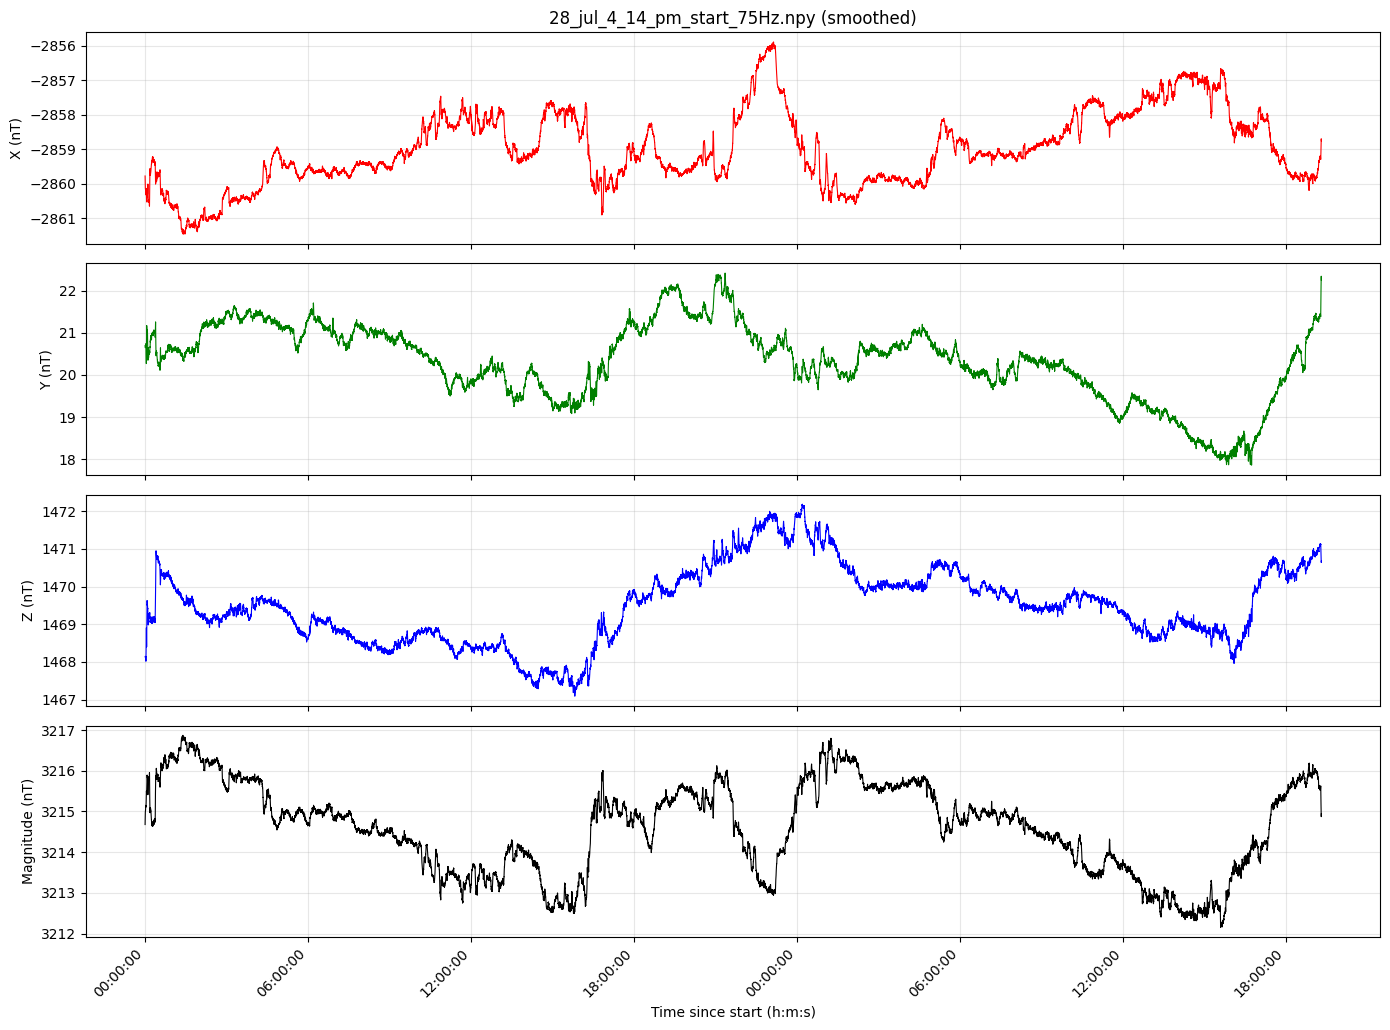

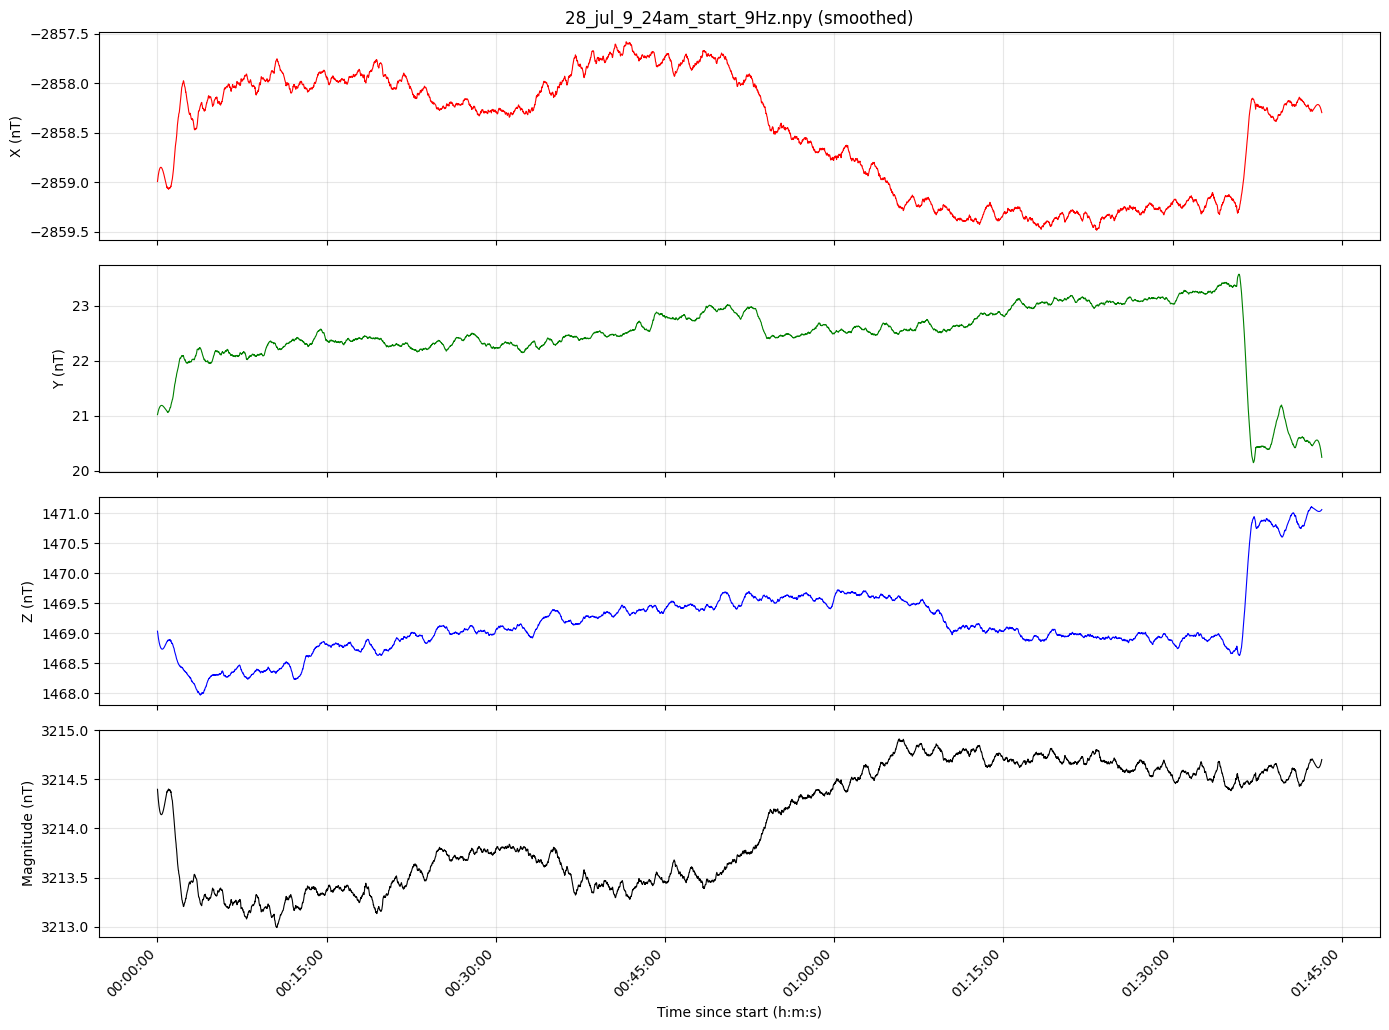

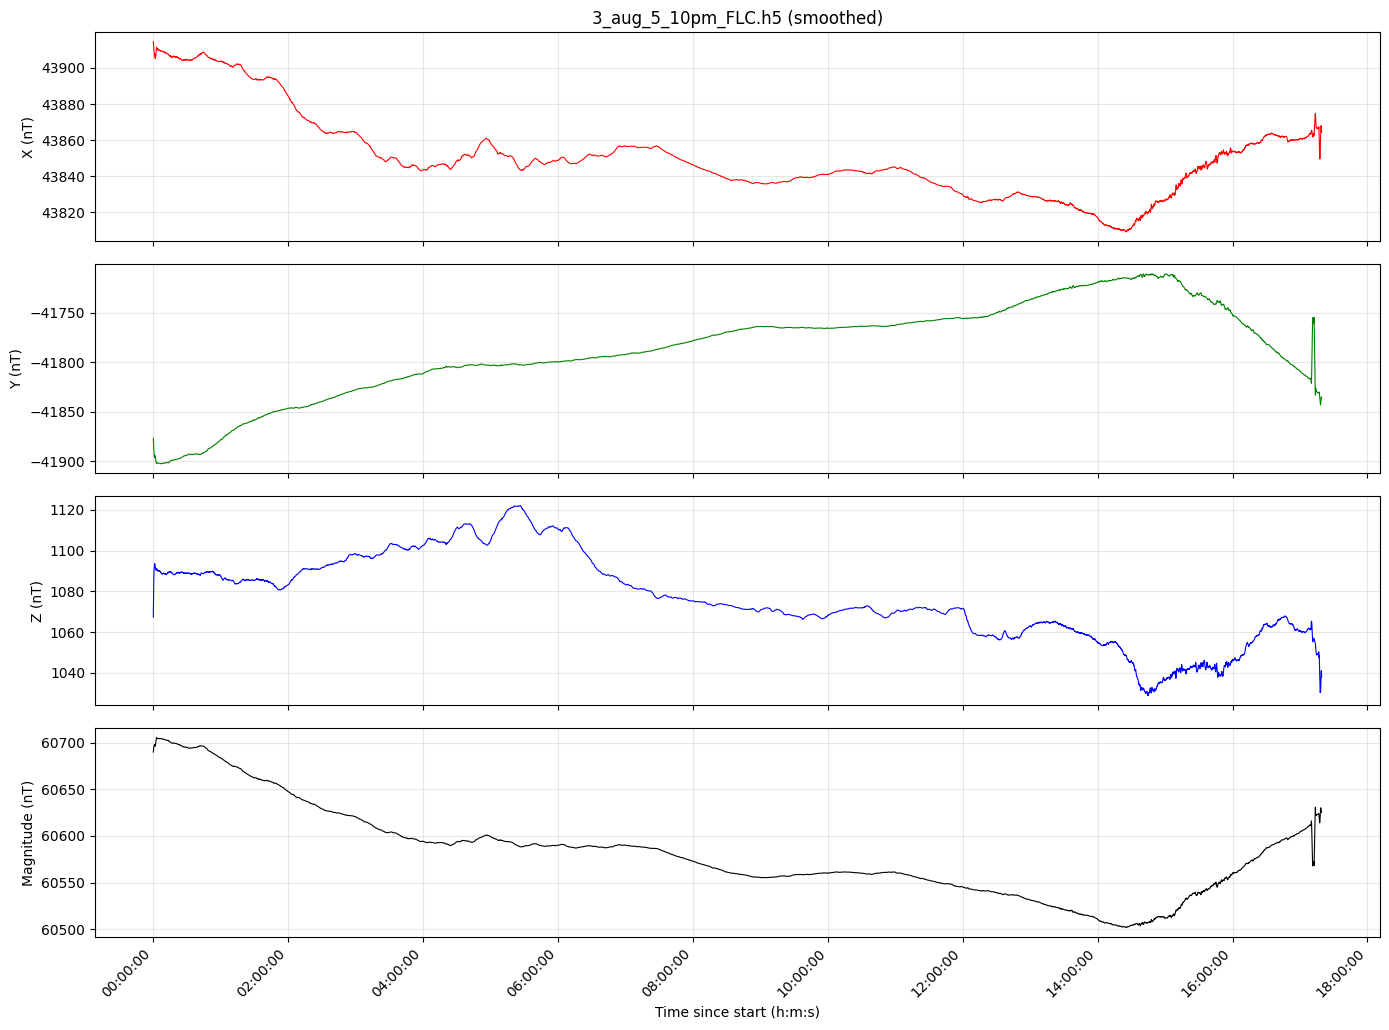

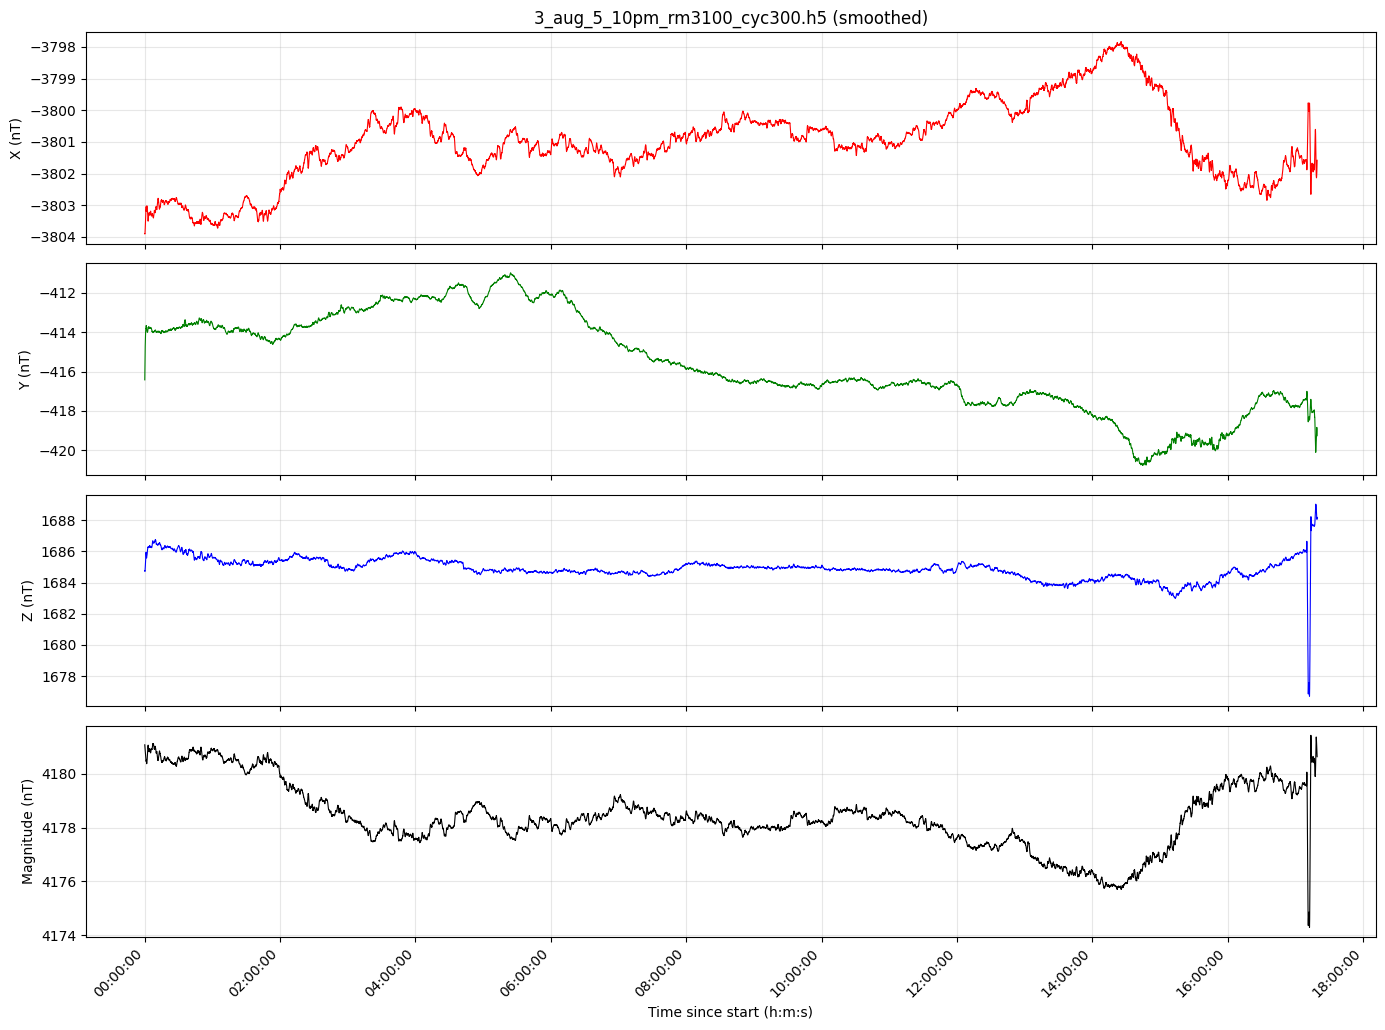

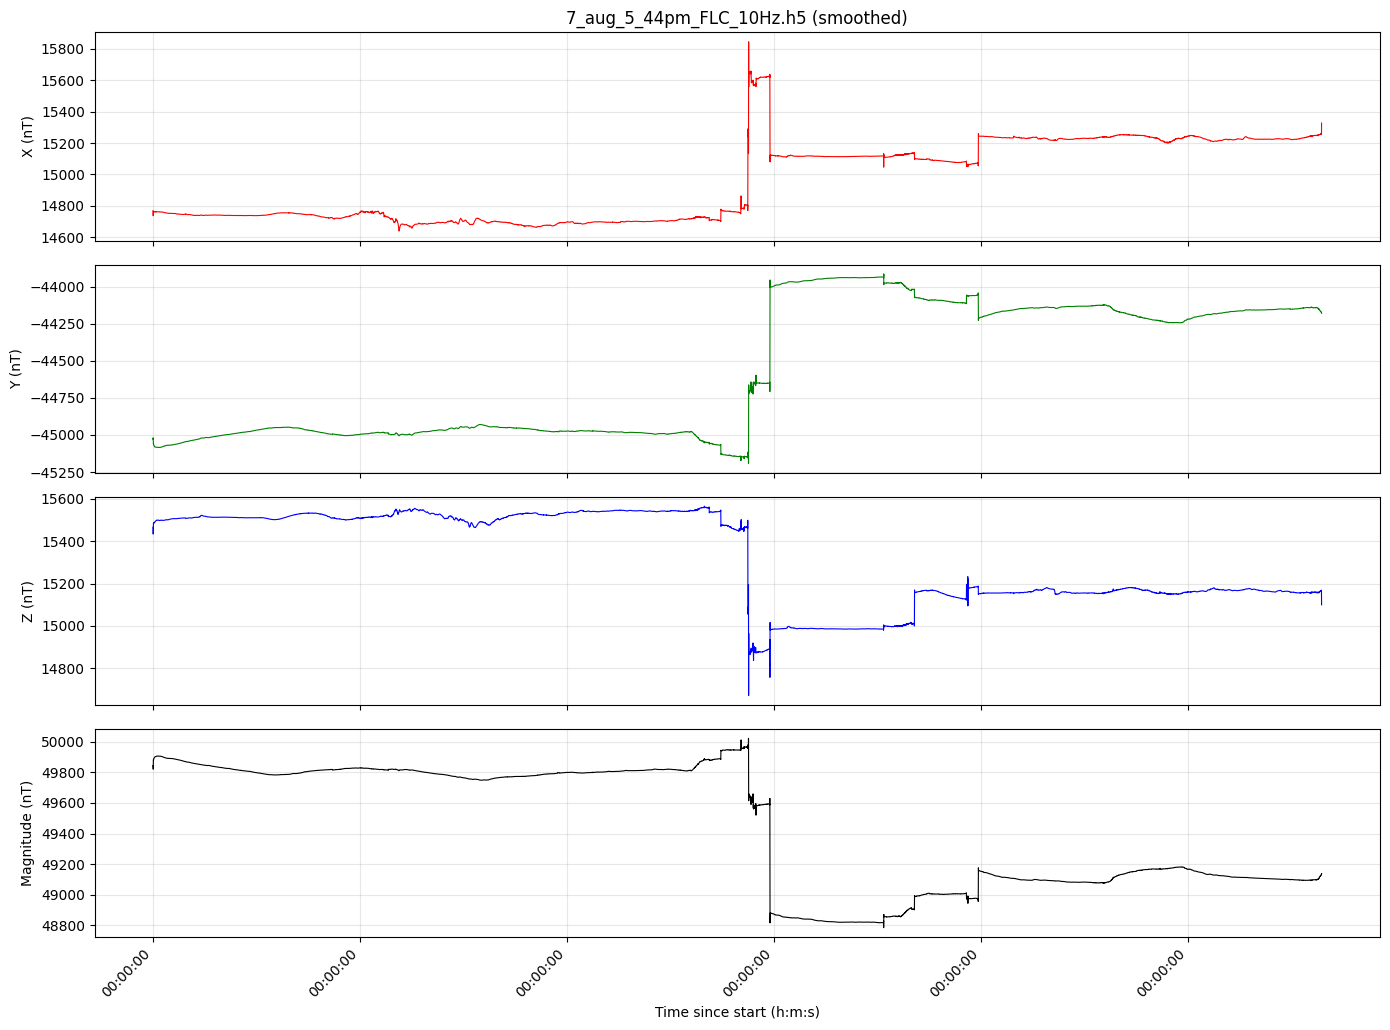

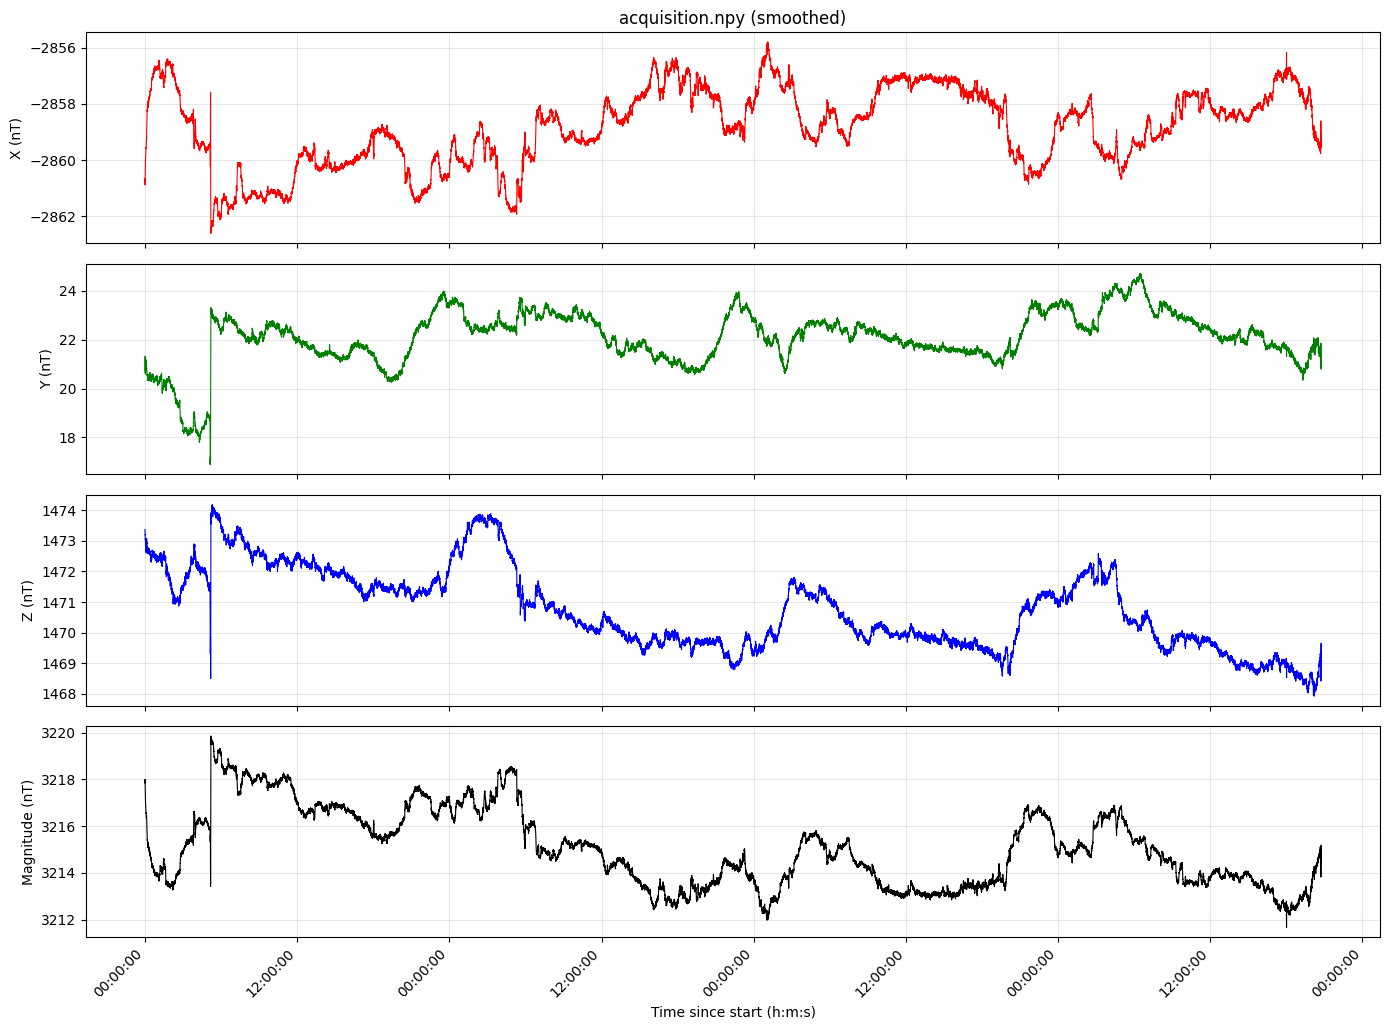

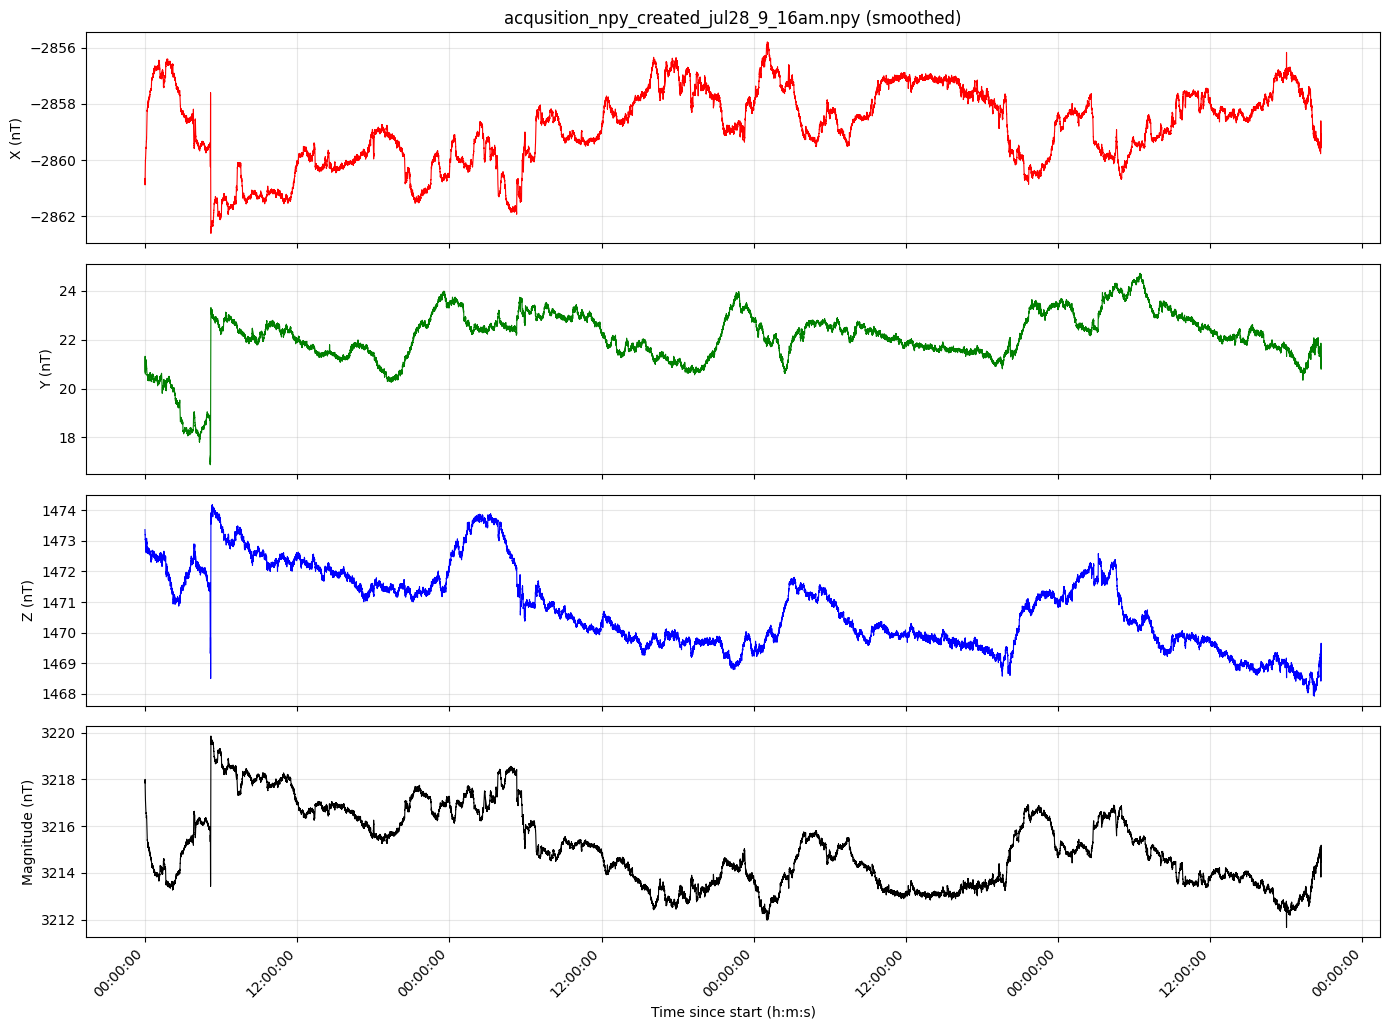

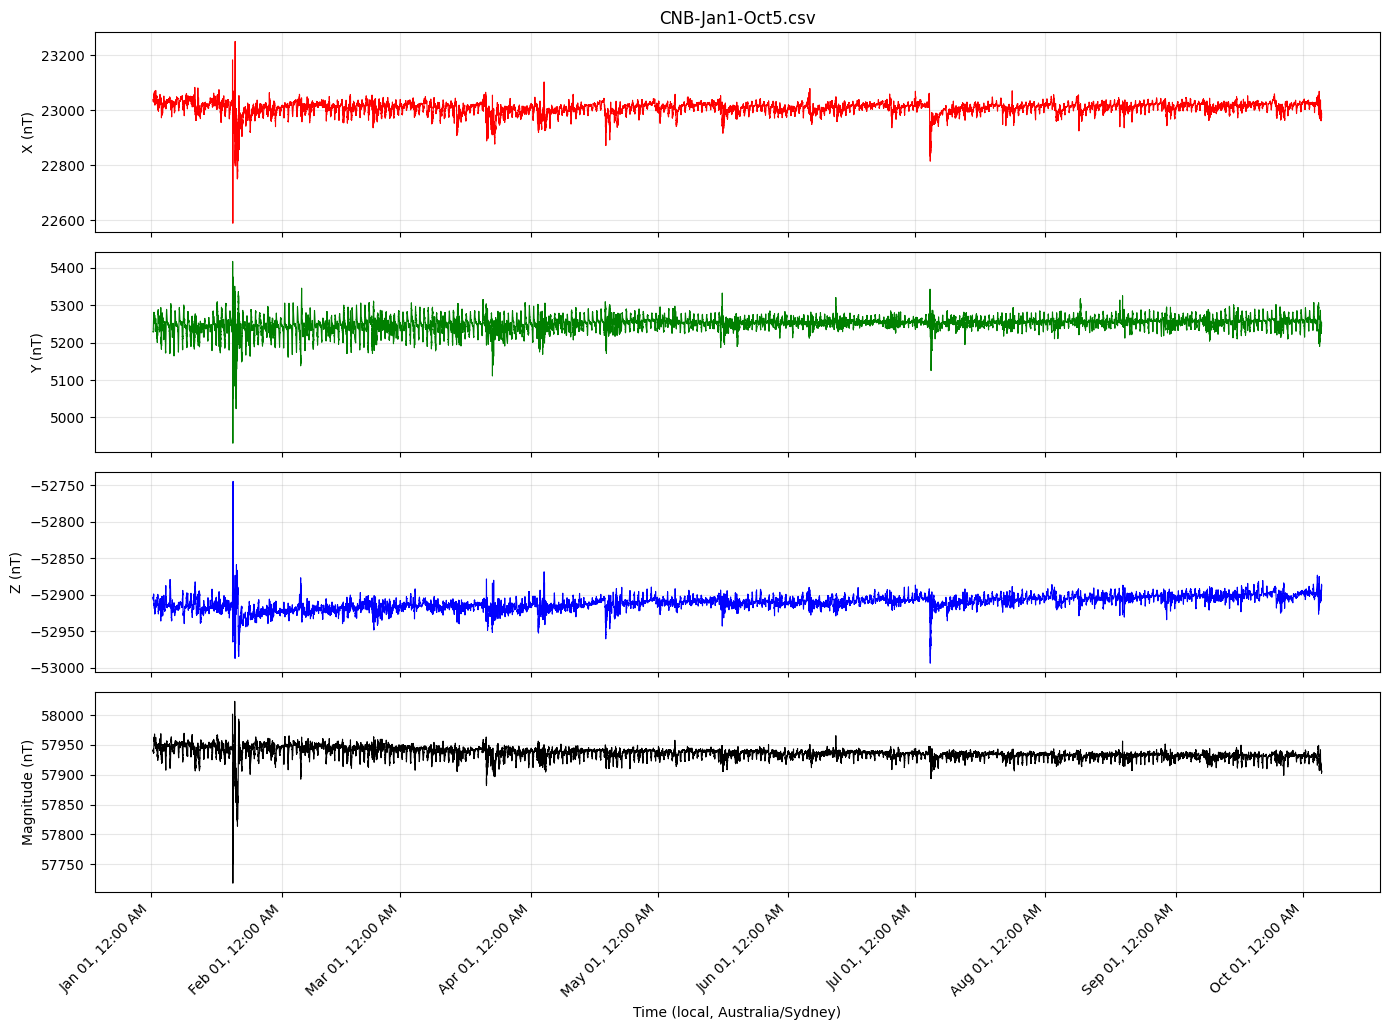

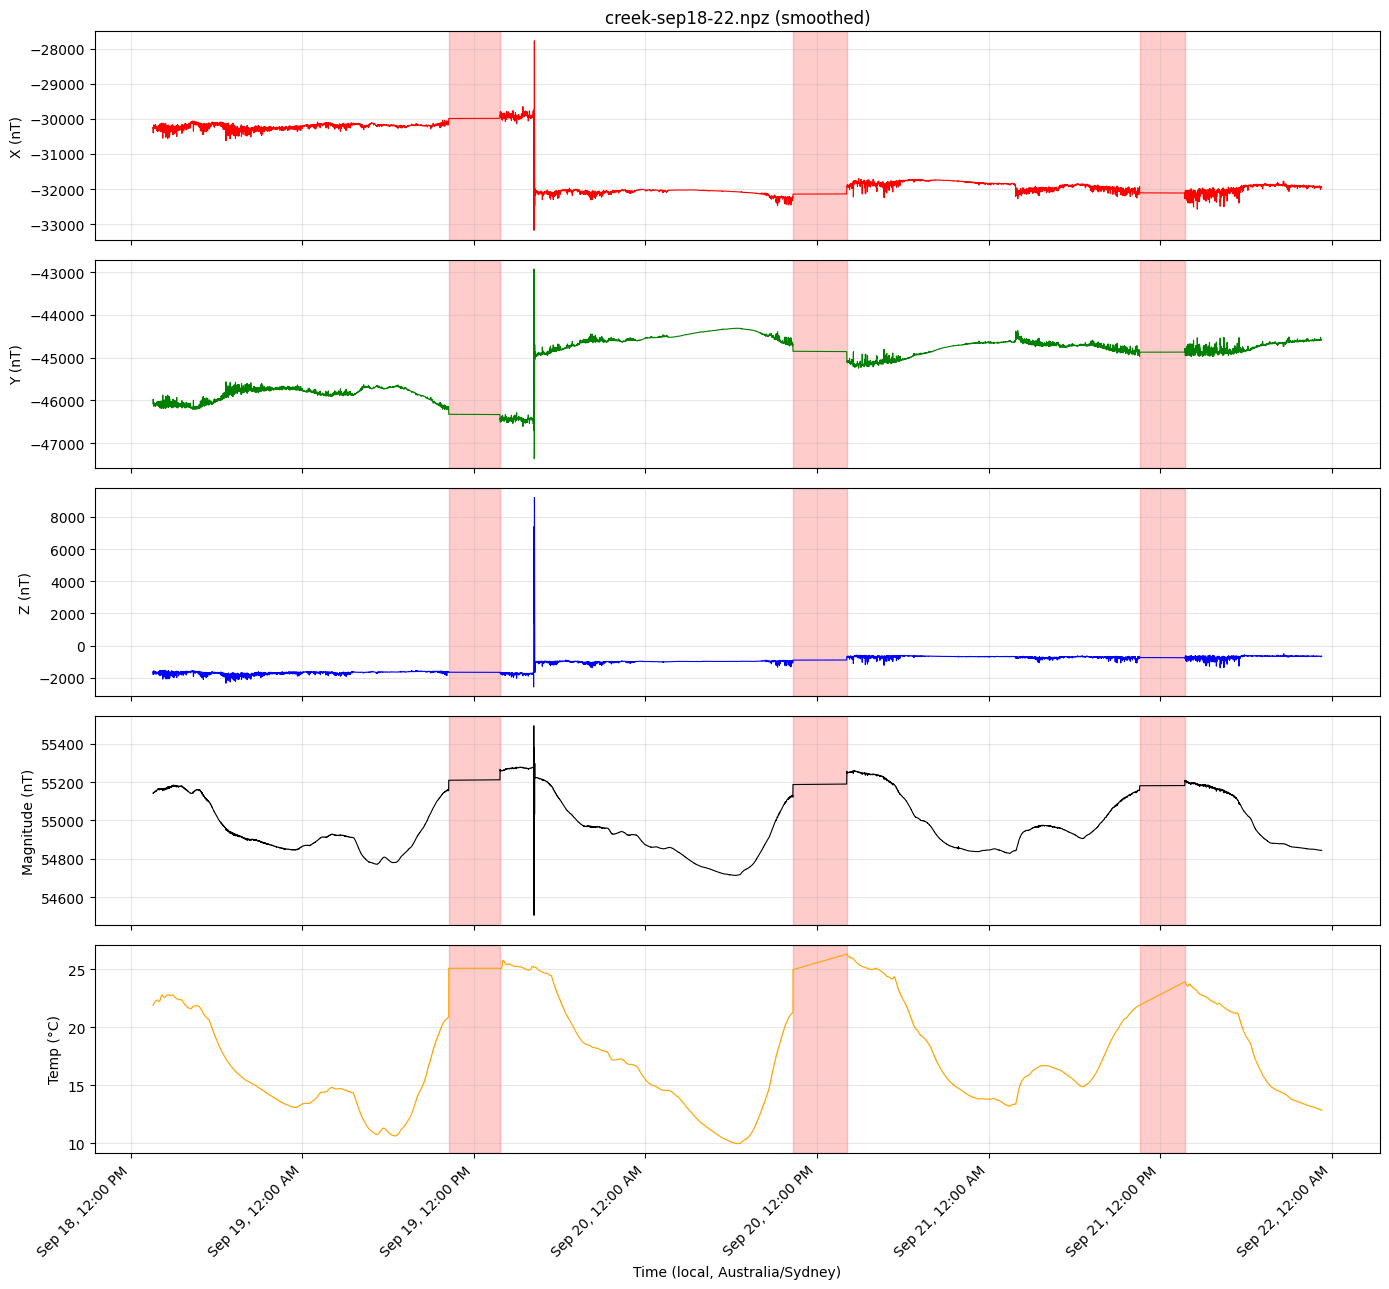

3 gap(s) > 10 min:
  2026-09-19 10:14:39+10:00 → 2026-09-19 13:49:38+10:00  (0 days 03:34:59)
  2026-09-20 10:19:26+10:00 → 2026-09-20 14:04:48+10:00  (0 days 03:45:22)
  2026-09-21 10:34:33+10:00 → 2026-09-21 13:43:50+10:00  (0 days 03:09:17)


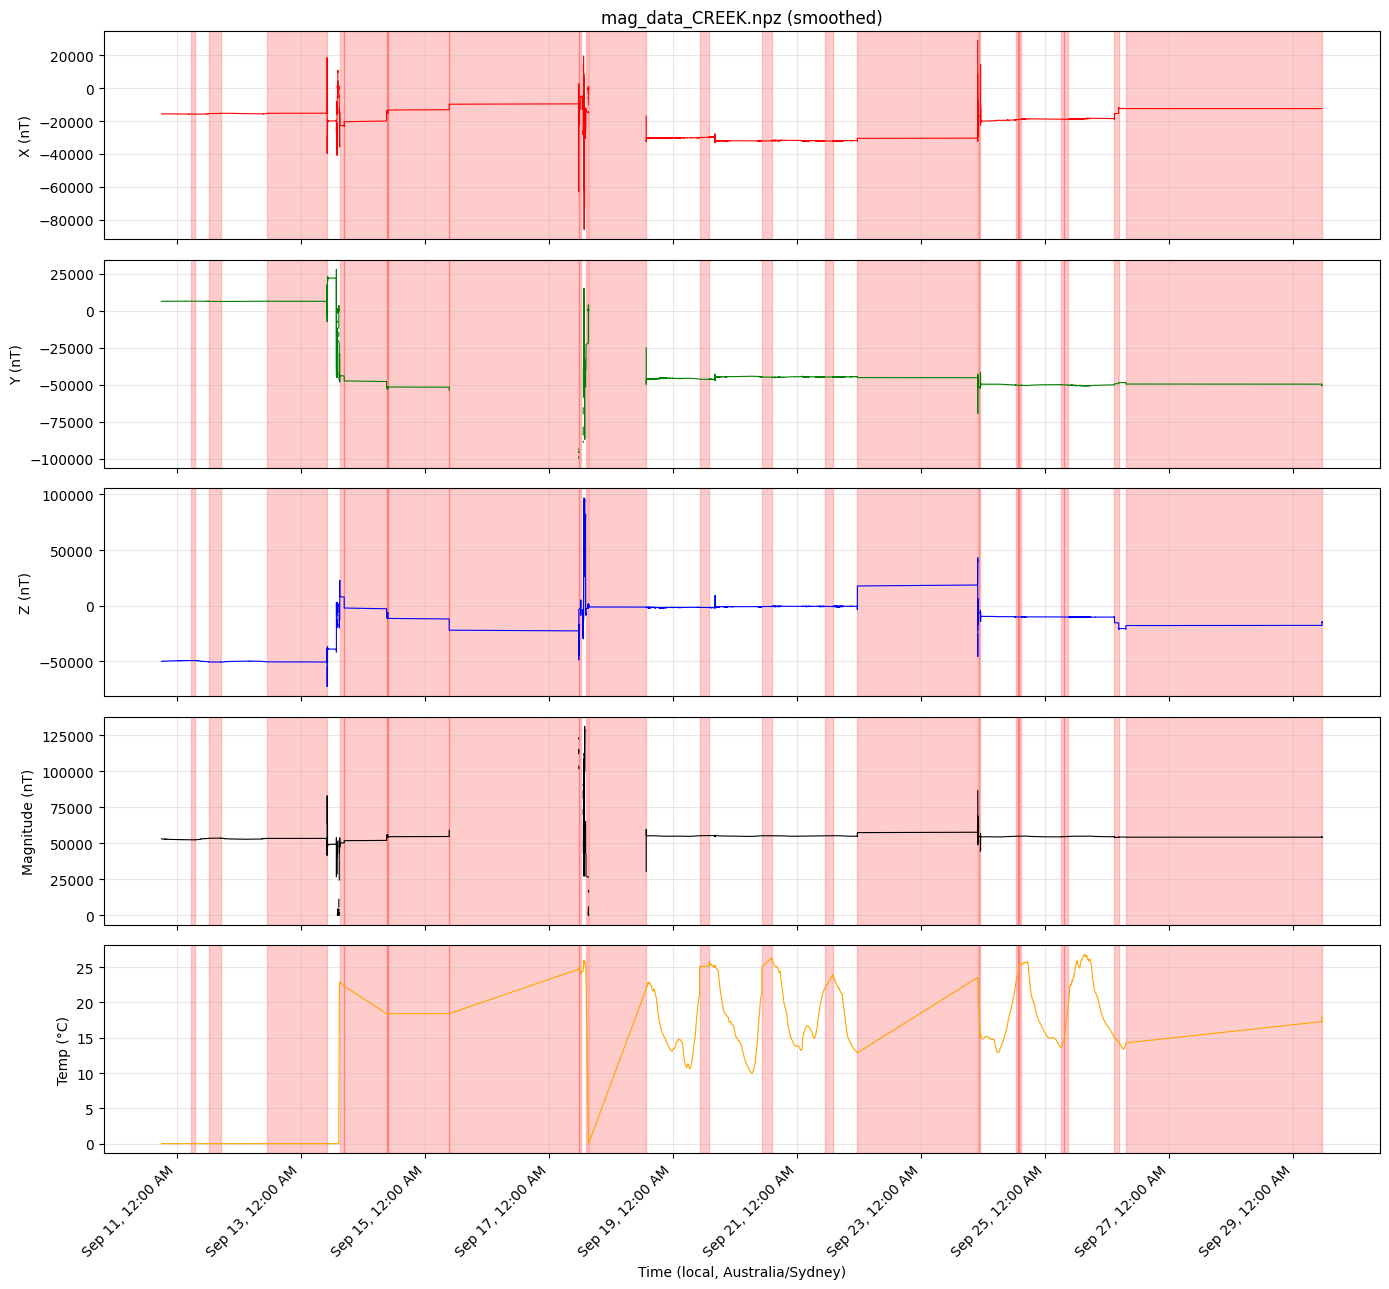

24 gap(s) > 10 min:
  2026-09-11 05:27:20+10:00 → 2026-09-11 06:55:50+10:00  (0 days 01:28:30)
  2026-09-11 12:10:40+10:00 → 2026-09-11 16:51:10+10:00  (0 days 04:40:30)
  2026-09-12 10:44:00+10:00 → 2026-09-13 09:57:08+10:00  (0 days 23:13:08)
  2026-09-13 14:57:52+10:00 → 2026-09-13 16:40:32+10:00  (0 days 01:42:40)
  2026-09-13 16:40:32+10:00 → 2026-09-14 09:05:11+10:00  (0 days 16:24:39)
  2026-09-14 09:05:11+10:00 → 2026-09-14 09:32:11+10:00  (0 days 00:27:00)
  2026-09-14 09:32:32+10:00 → 2026-09-15 09:18:20+10:00  (0 days 23:45:48)
  2026-09-15 09:18:21+10:00 → 2026-09-17 11:22:35+10:00  (2 days 02:04:14)
  2026-09-17 11:29:25+10:00 → 2026-09-17 12:14:47+10:00  (0 days 00:45:22)
  2026-09-17 14:15:37+10:00 → 2026-09-17 15:10:38+10:00  (0 days 00:55:01)
  ... and 14 more


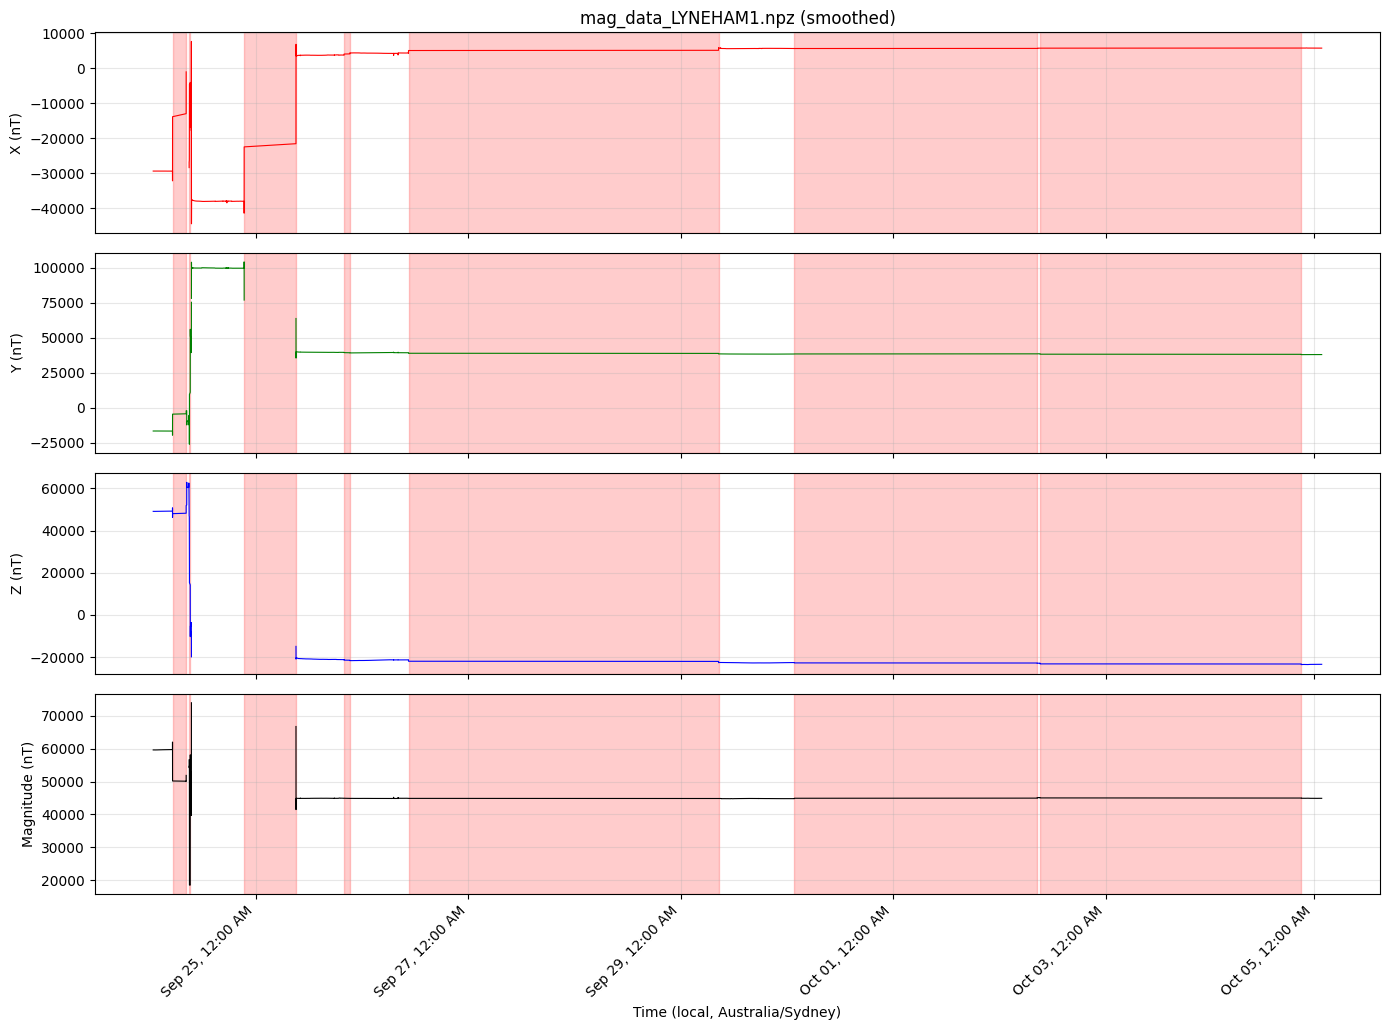

7 gap(s) > 10 min:
  2026-09-24 05:13:19+10:00 → 2026-09-24 08:17:42+10:00  (0 days 03:04:23)
  2026-09-24 09:02:19+10:00 → 2026-09-24 09:12:53+10:00  (0 days 00:10:34)
  2026-09-24 21:23:56+10:00 → 2026-09-25 09:06:13+10:00  (0 days 11:42:17)
  2026-09-25 19:59:07+10:00 → 2026-09-25 21:16:49+10:00  (0 days 01:17:42)
  2026-09-26 10:31:48+10:00 → 2026-09-29 08:34:12+10:00  (2 days 22:02:24)
  2026-09-30 01:42:40+10:00 → 2026-10-02 08:32:24+10:00  (2 days 06:49:44)
  2026-10-02 09:12:52+10:00 → 2026-10-04 21:13:51+11:00  (2 days 11:00:59)


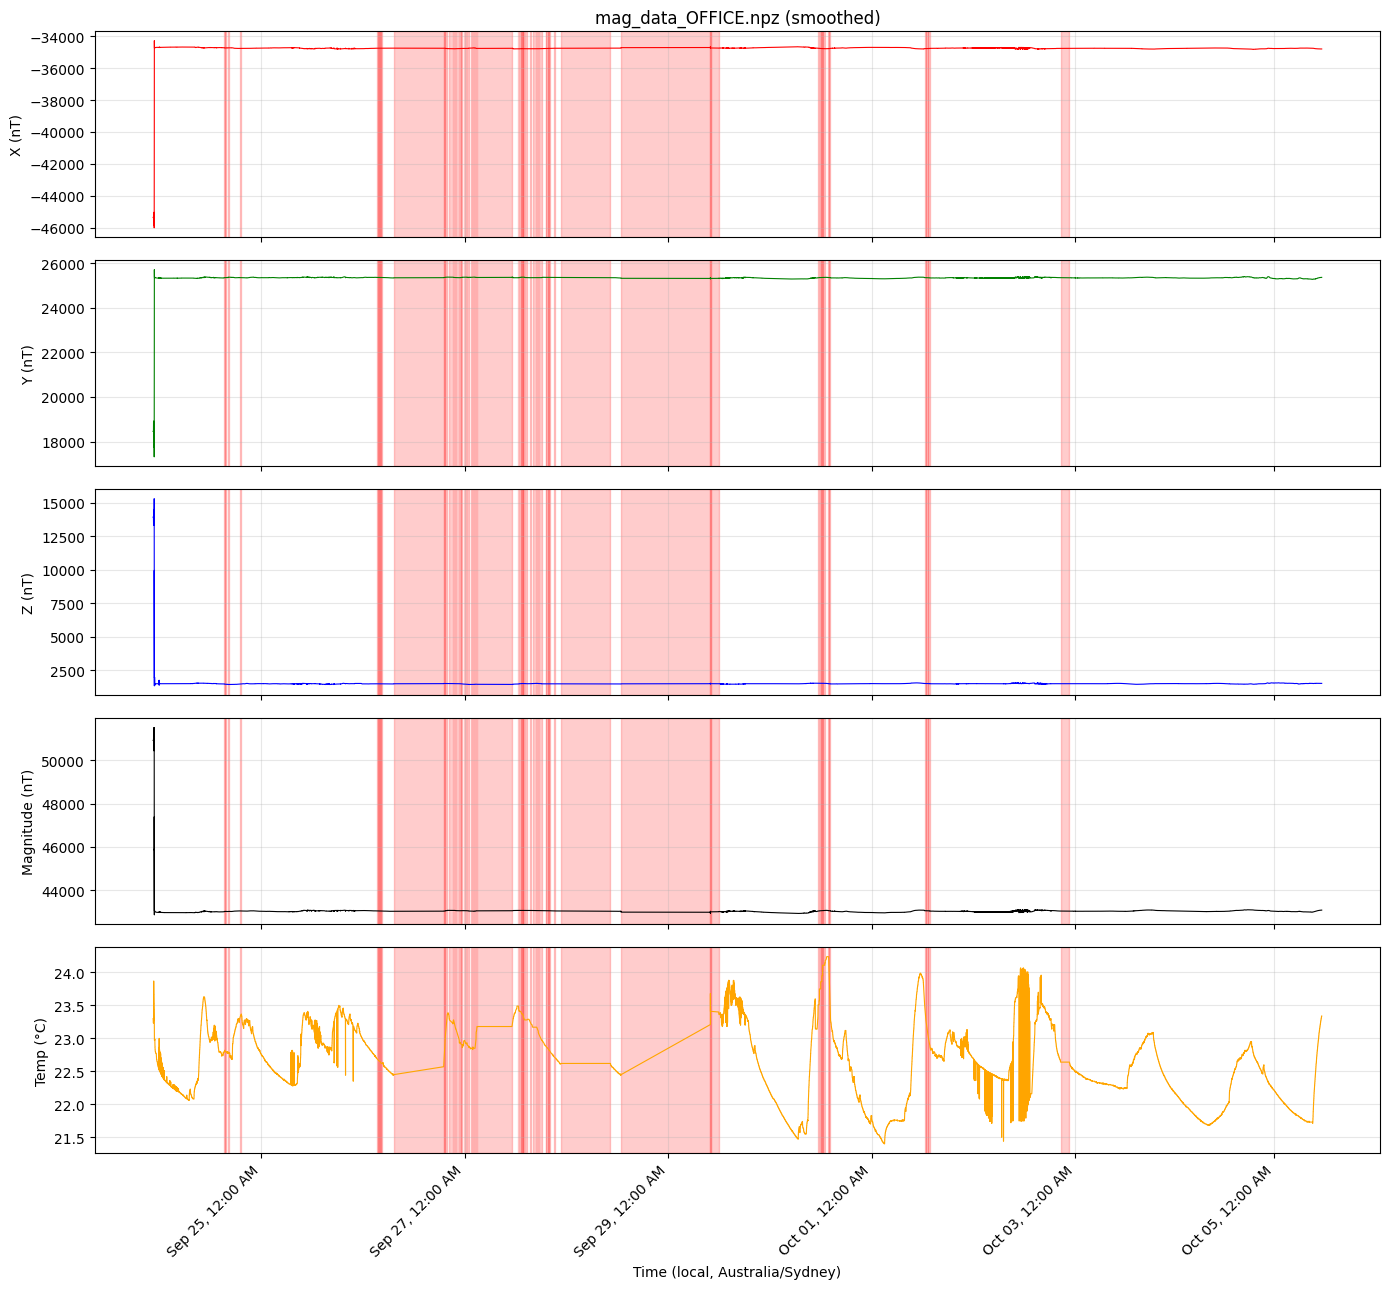

55 gap(s) > 10 min:
  2026-09-24 15:07:23+10:00 → 2026-09-24 15:18:15+10:00  (0 days 00:10:52)
  2026-09-24 15:20:03+10:00 → 2026-09-24 15:42:55+10:00  (0 days 00:22:52)
  2026-09-24 16:07:13+10:00 → 2026-09-24 16:18:15+10:00  (0 days 00:11:02)
  2026-09-24 18:59:28+10:00 → 2026-09-24 19:13:55+10:00  (0 days 00:14:27)
  2026-09-26 03:09:24+10:00 → 2026-09-26 03:25:44+10:00  (0 days 00:16:20)
  2026-09-26 03:25:44+10:00 → 2026-09-26 03:41:54+10:00  (0 days 00:16:10)
  2026-09-26 03:41:54+10:00 → 2026-09-26 03:58:05+10:00  (0 days 00:16:11)
  2026-09-26 03:58:05+10:00 → 2026-09-26 04:14:04+10:00  (0 days 00:15:59)
  2026-09-26 04:14:04+10:00 → 2026-09-26 04:31:04+10:00  (0 days 00:17:00)
  2026-09-26 07:12:23+10:00 → 2026-09-26 18:58:22+10:00  (0 days 11:45:59)
  ... and 45 more


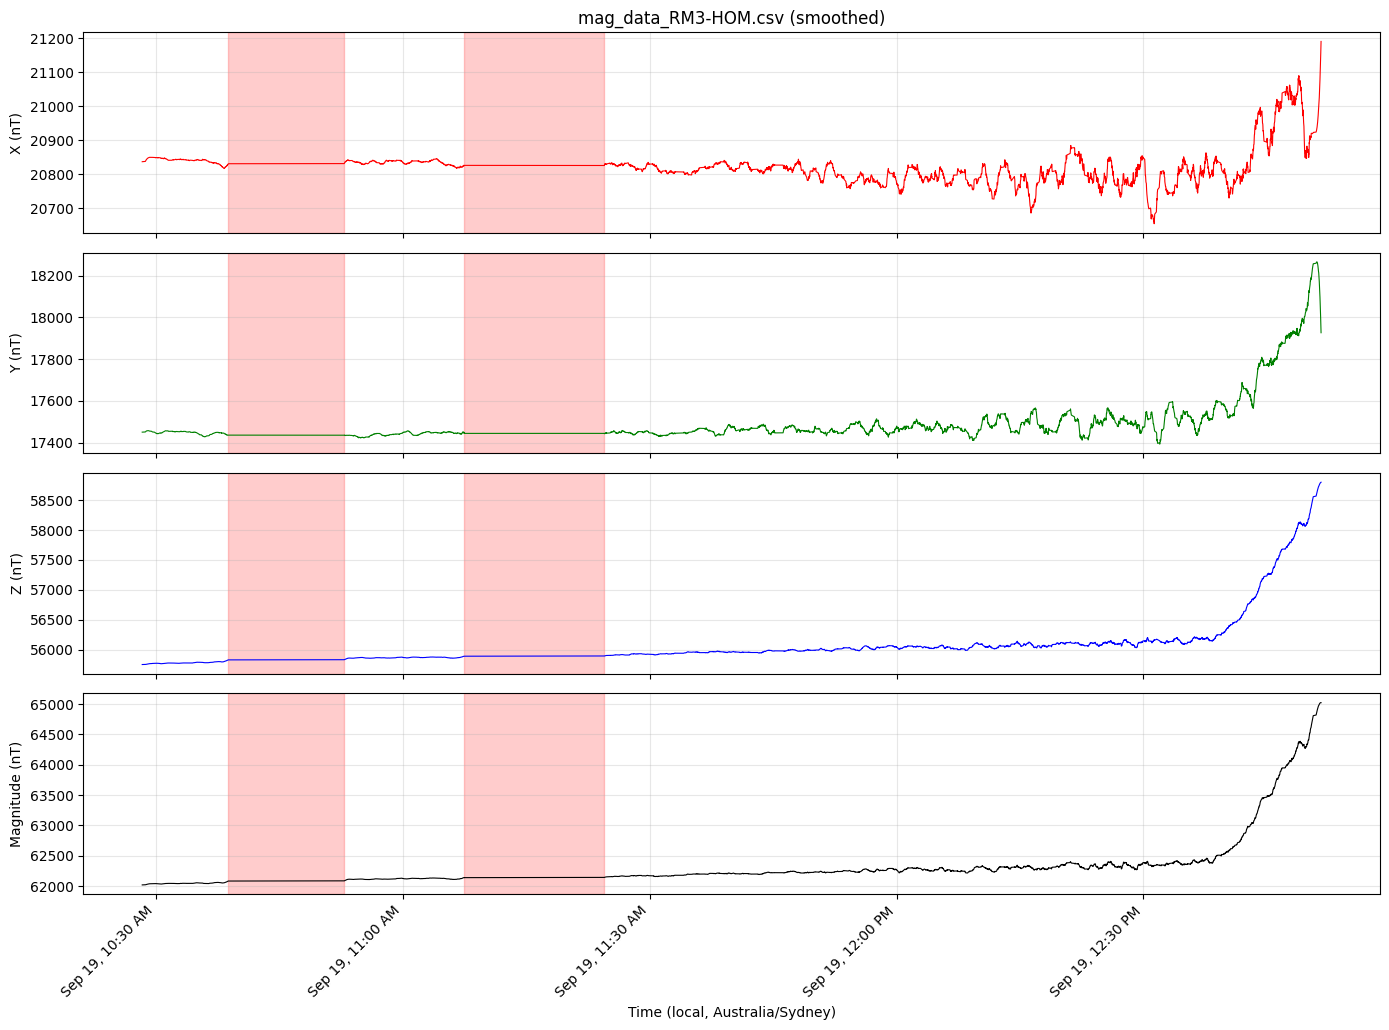

2 gap(s) > 10 min:
  2026-09-19 10:38:47+10:00 → 2026-09-19 10:52:52+10:00  (0 days 00:14:05)
  2026-09-19 11:07:29+10:00 → 2026-09-19 11:24:29+10:00  (0 days 00:17:00)


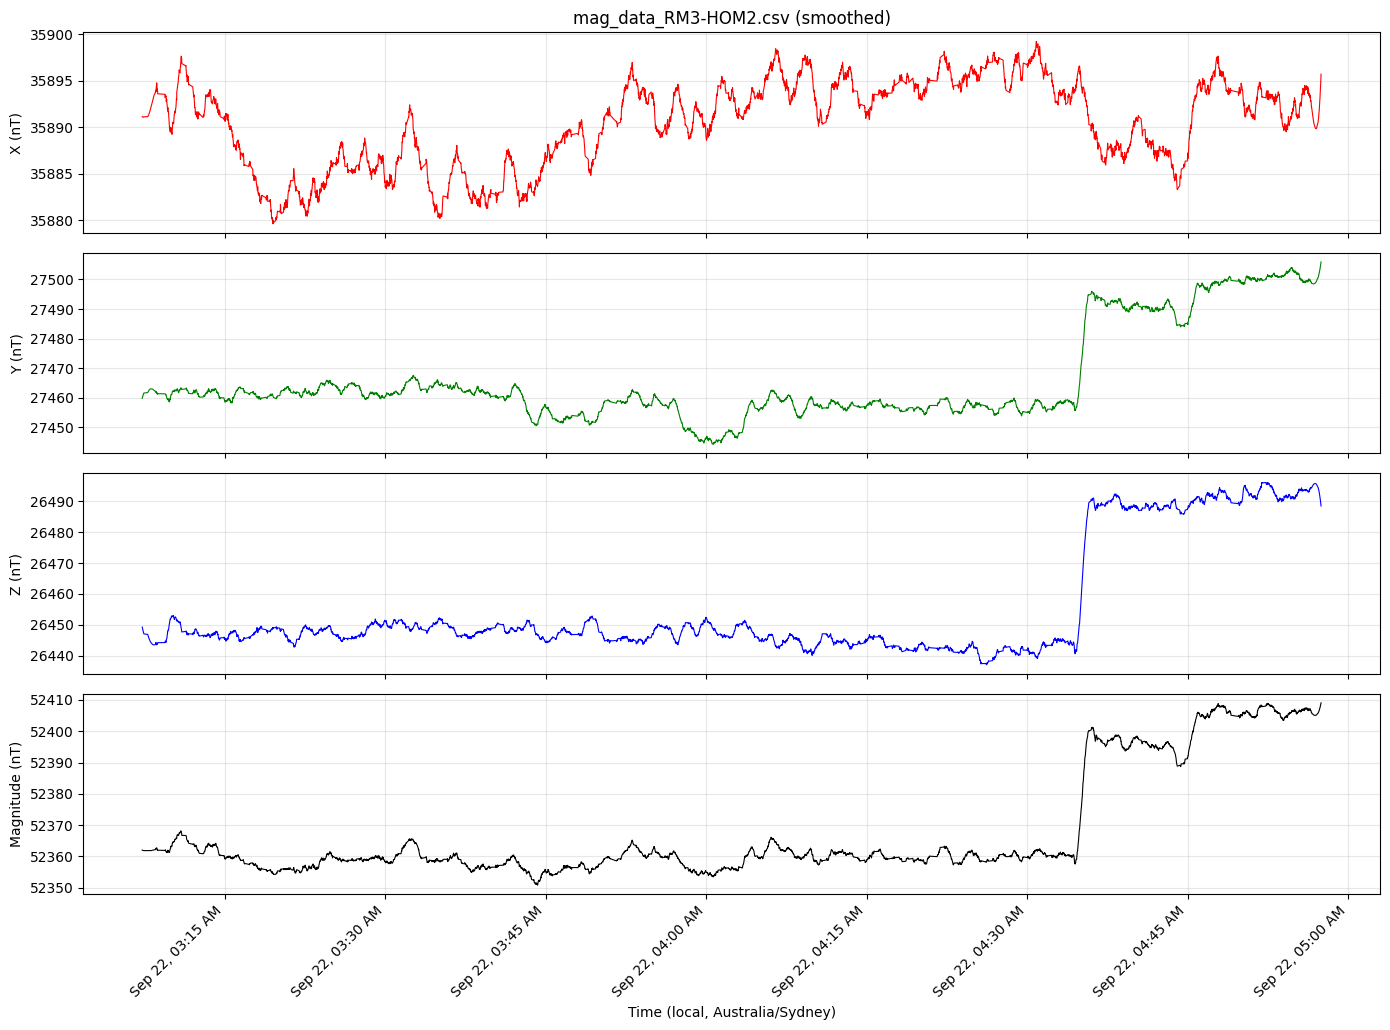

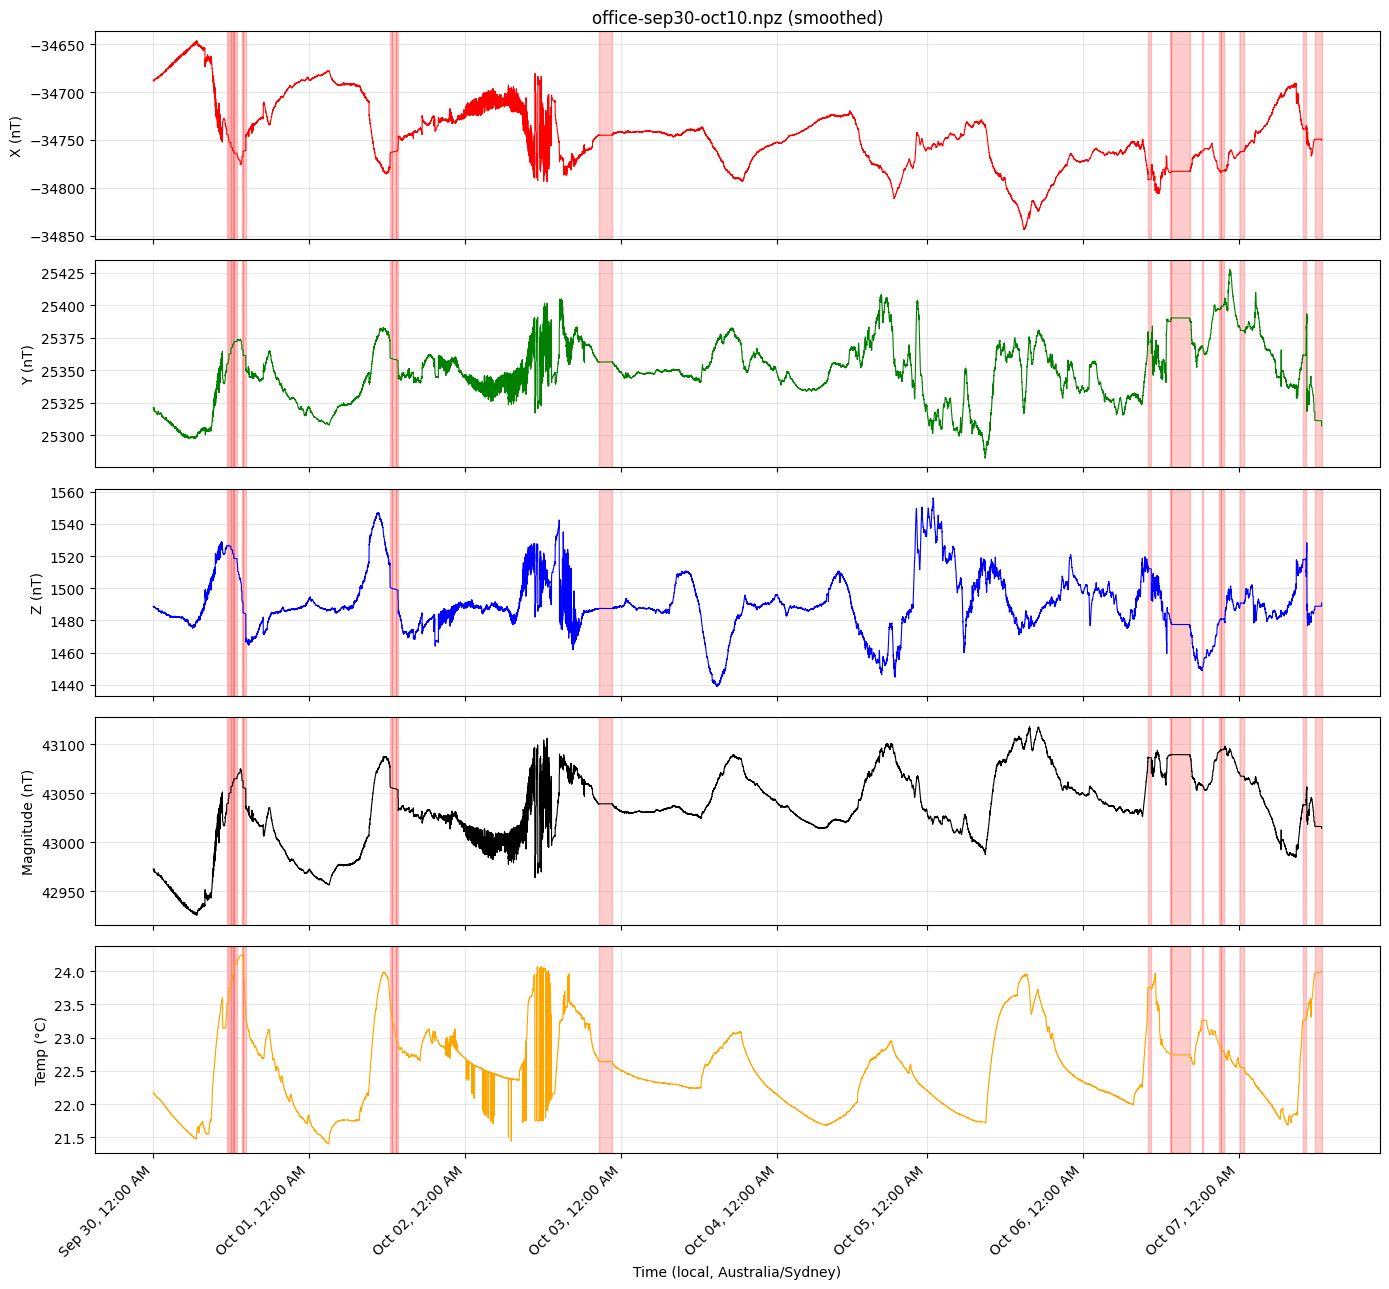

20 gap(s) > 10 min:
  2026-09-30 11:20:20+10:00 → 2026-09-30 11:33:17+10:00  (0 days 00:12:57)
  2026-09-30 11:40:40+10:00 → 2026-09-30 11:56:45+10:00  (0 days 00:16:05)
  2026-09-30 12:02:00+10:00 → 2026-09-30 12:12:37+10:00  (0 days 00:10:37)
  2026-09-30 12:12:46+10:00 → 2026-09-30 12:23:47+10:00  (0 days 00:11:01)
  2026-09-30 12:23:56+10:00 → 2026-09-30 12:53:37+10:00  (0 days 00:29:41)
  2026-09-30 13:38:26+10:00 → 2026-09-30 13:48:57+10:00  (0 days 00:10:31)
  2026-09-30 13:49:06+10:00 → 2026-09-30 14:13:50+10:00  (0 days 00:24:44)
  2026-10-01 12:28:21+10:00 → 2026-10-01 12:46:39+10:00  (0 days 00:18:18)
  2026-10-01 12:46:39+10:00 → 2026-10-01 13:22:09+10:00  (0 days 00:35:30)
  2026-10-01 13:22:09+10:00 → 2026-10-01 13:38:49+10:00  (0 days 00:16:40)
  ... and 10 more


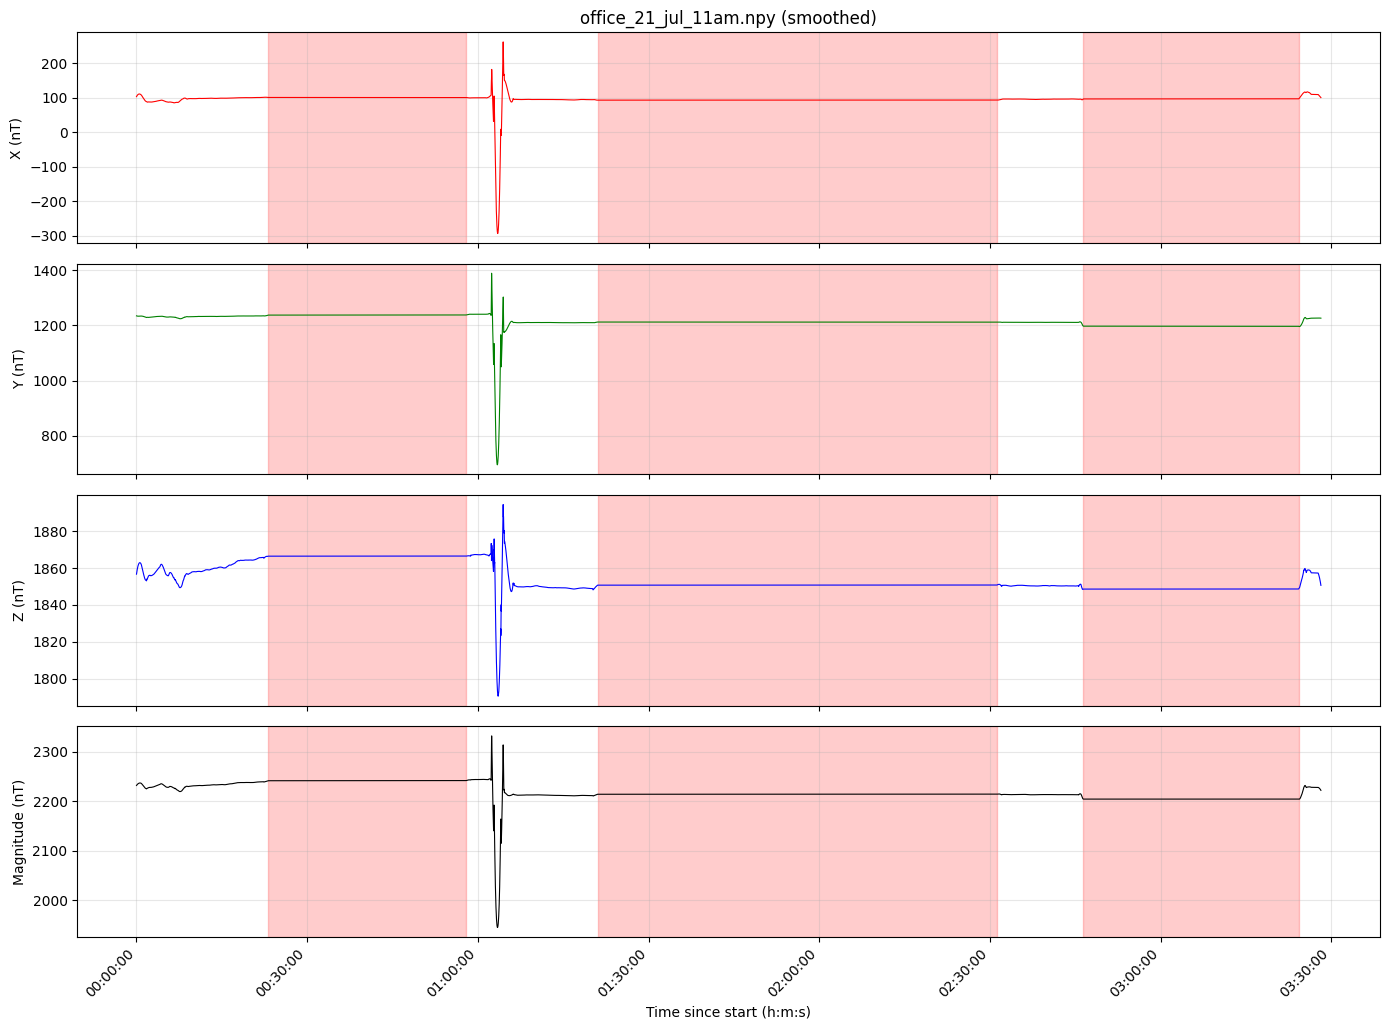

3 gap(s) > 10 min:
  2000-01-01 00:23:11+11:00 → 2000-01-01 00:57:54+11:00  (0 days 00:34:43)
  2000-01-01 01:21:03+11:00 → 2000-01-01 02:31:15+11:00  (0 days 01:10:12)
  2000-01-01 02:46:25+11:00 → 2000-01-01 03:24:16+11:00  (0 days 00:37:51)


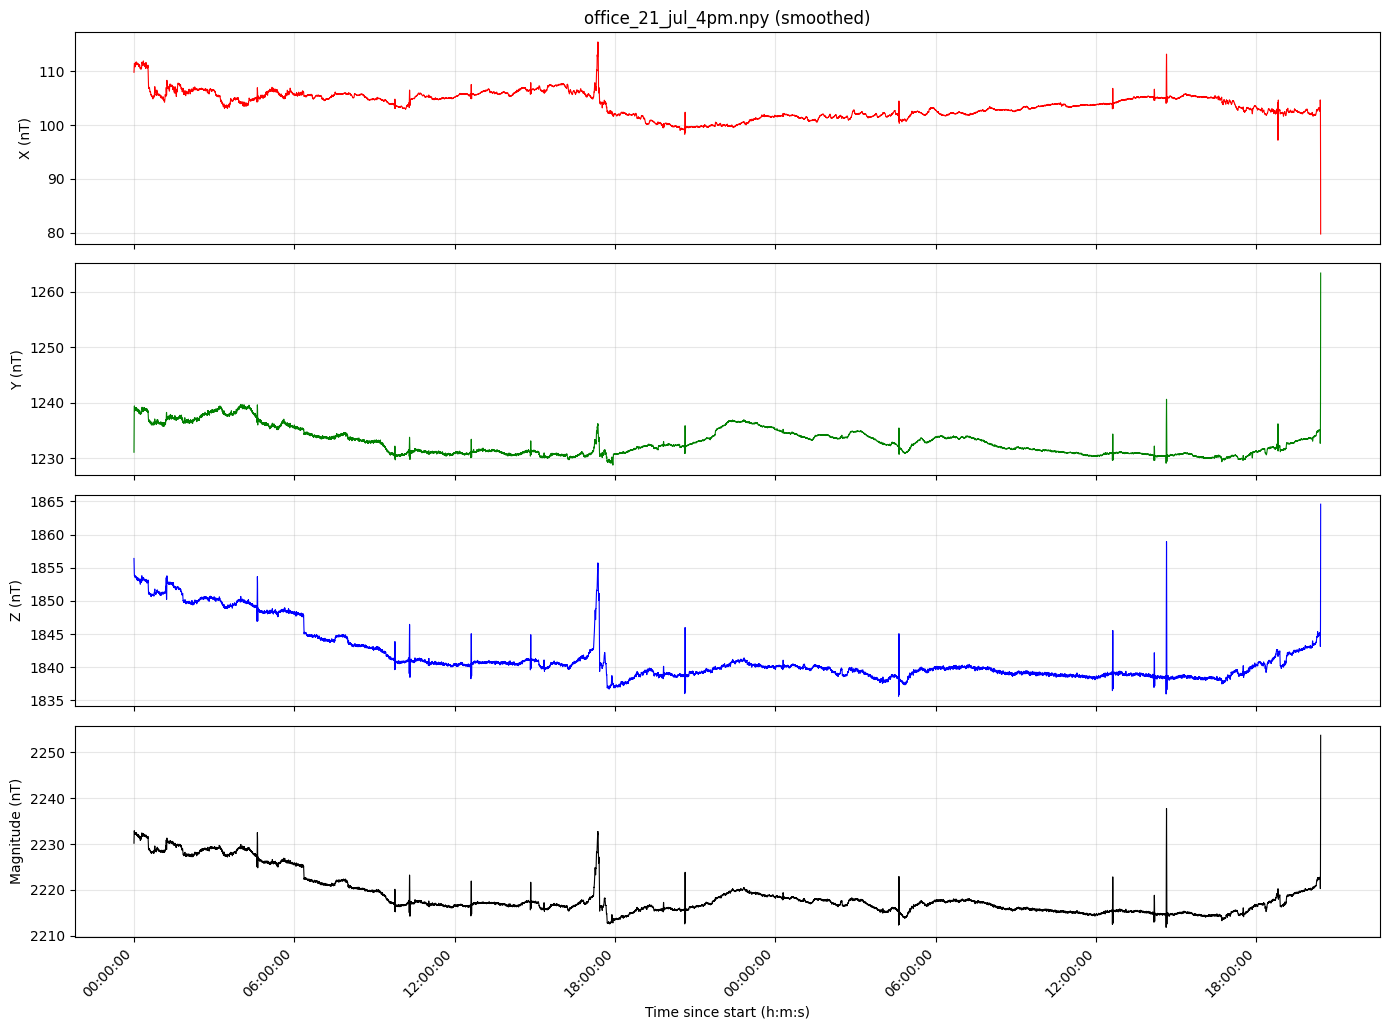

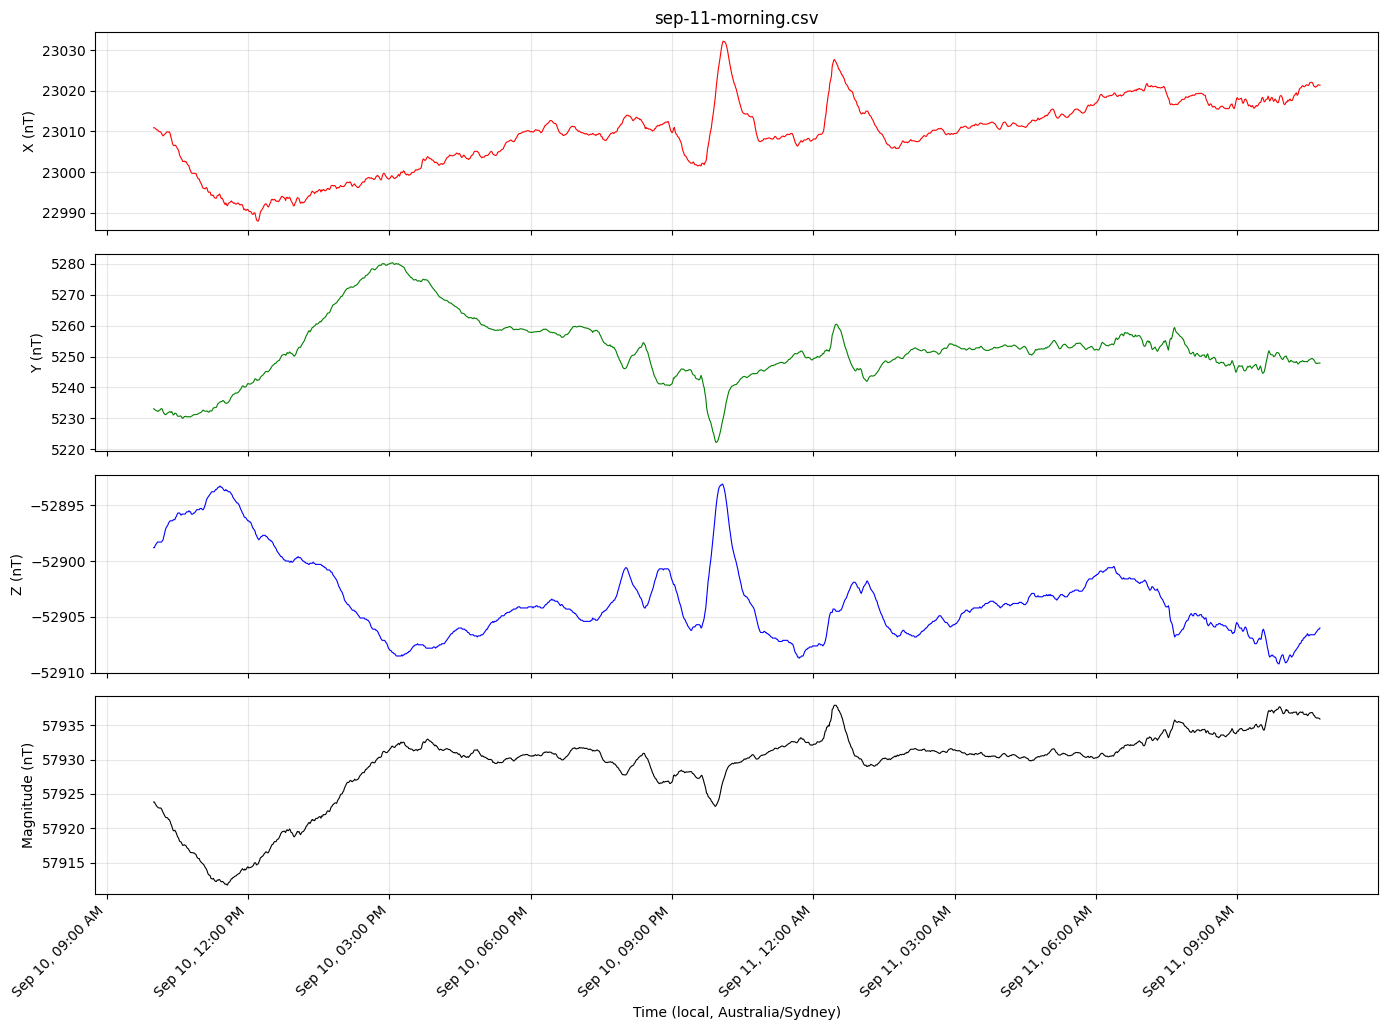

In [19]:
plot_folder("data")

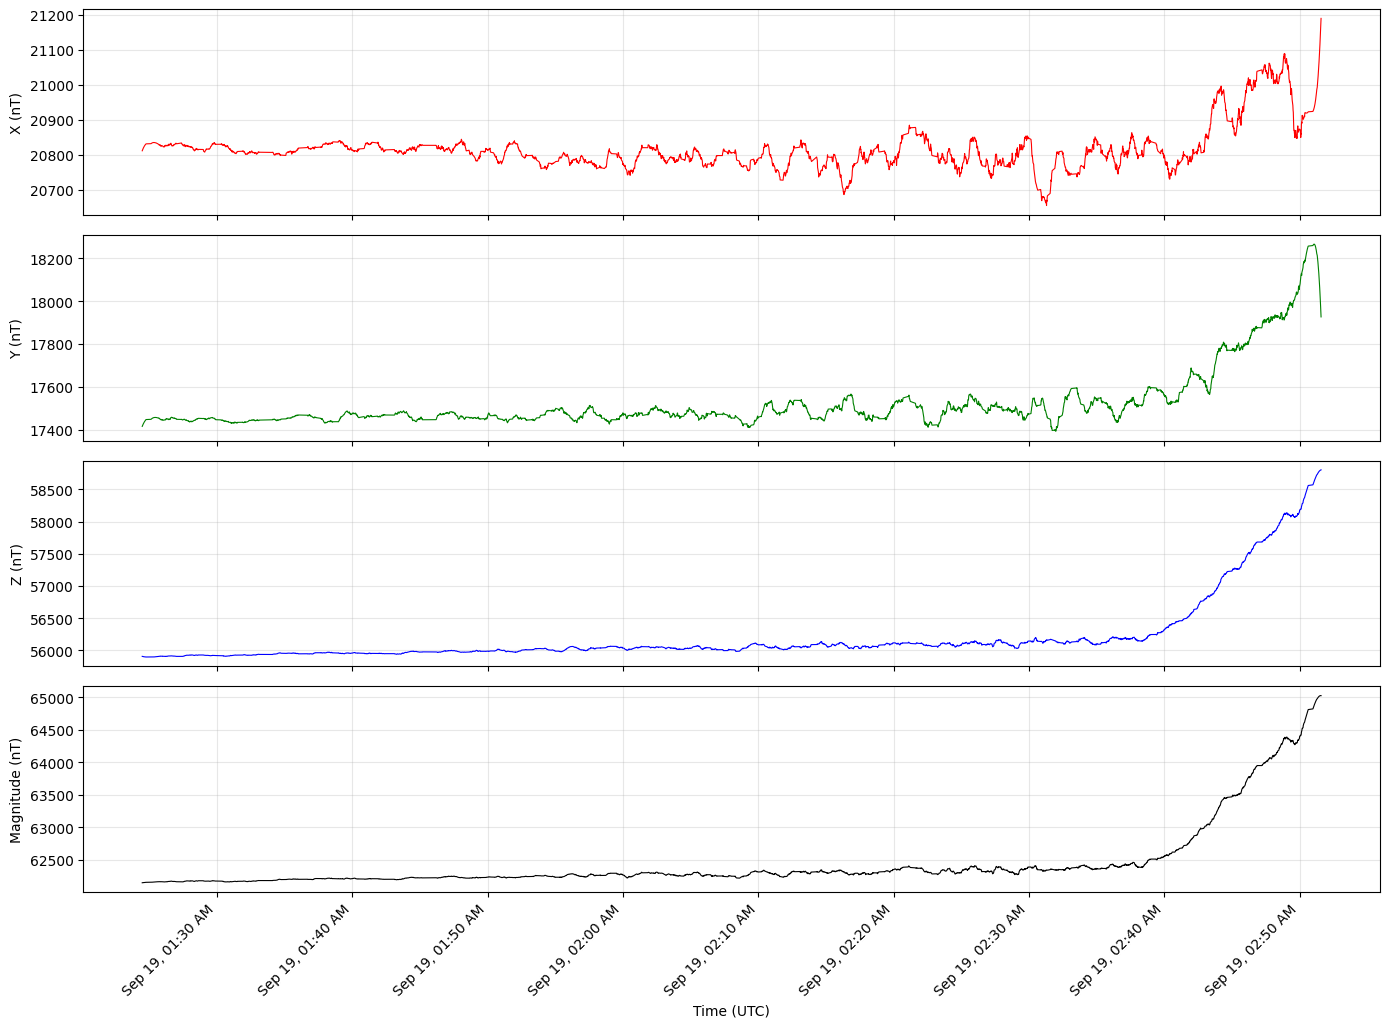

In [20]:
plot_data('data/mag_data_RM3-HOM.csv', start="2026-09-19 11:24:29+10:00", use_utc=True, no_title=True)

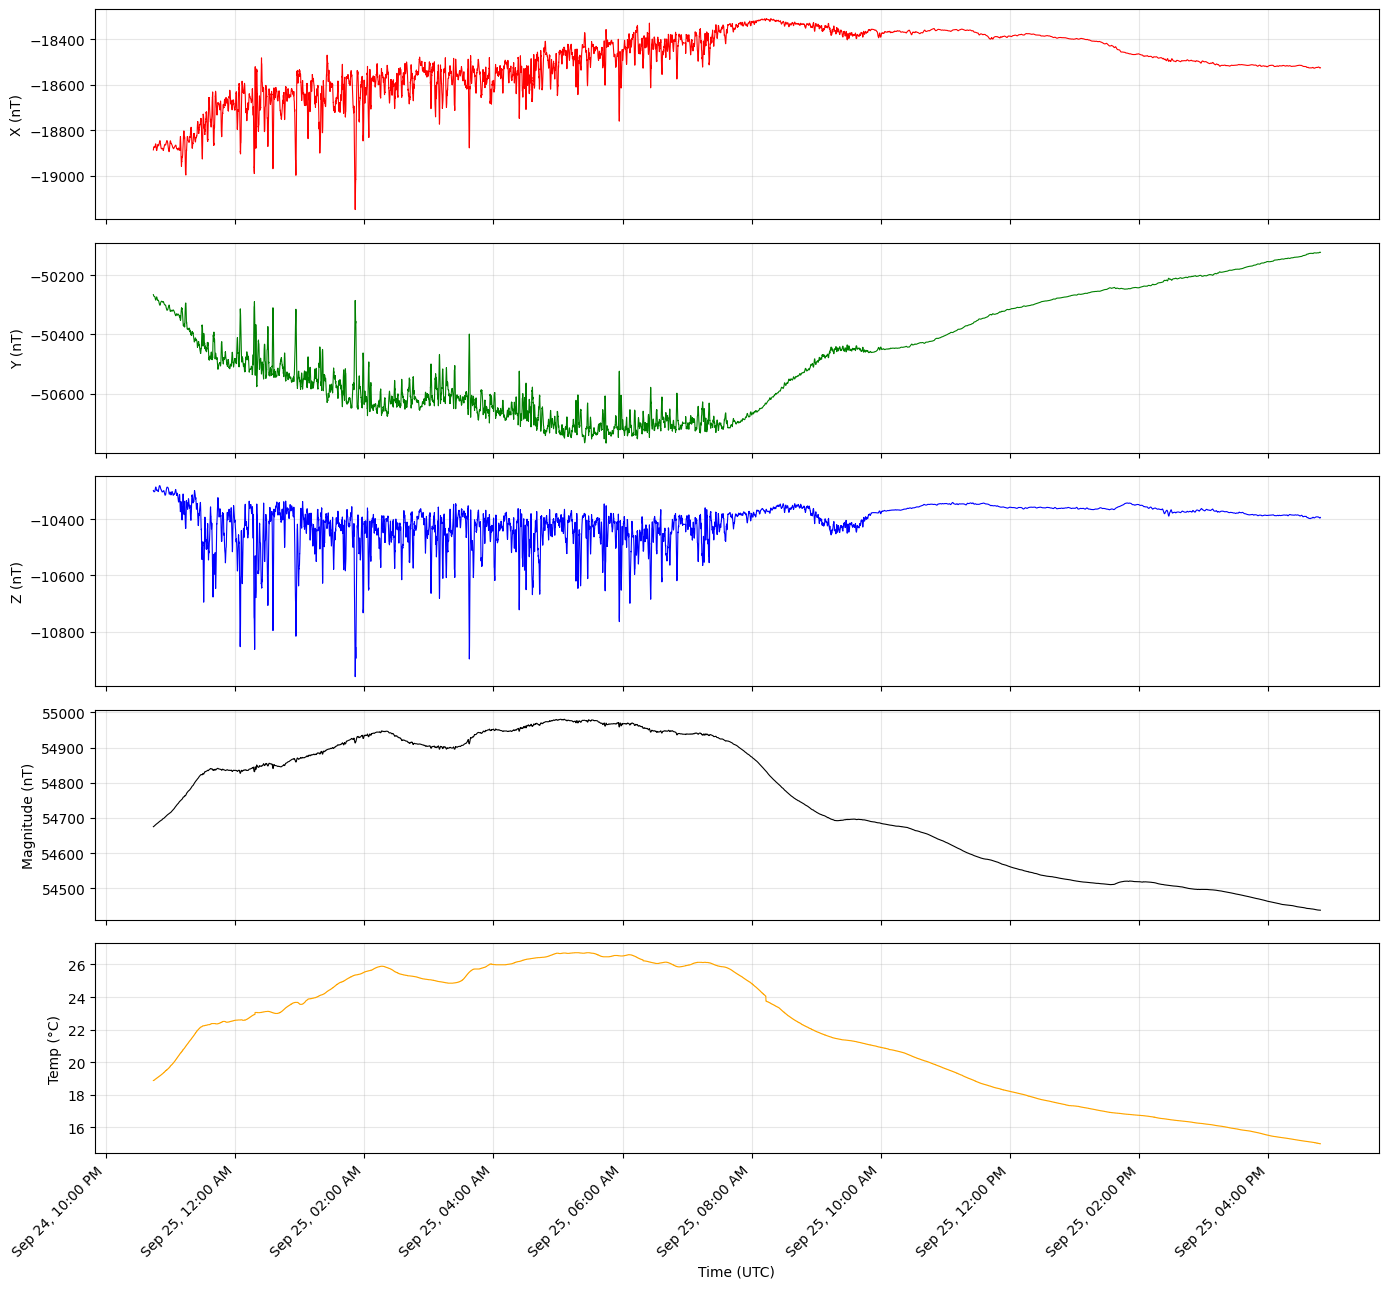

In [21]:
plot_data('data/mag_data_CREEK.npz', start="2026-09-25 08:43:58+10:00", end="2026-09-25 16:48:23+00:00", no_title=True, use_utc=True)

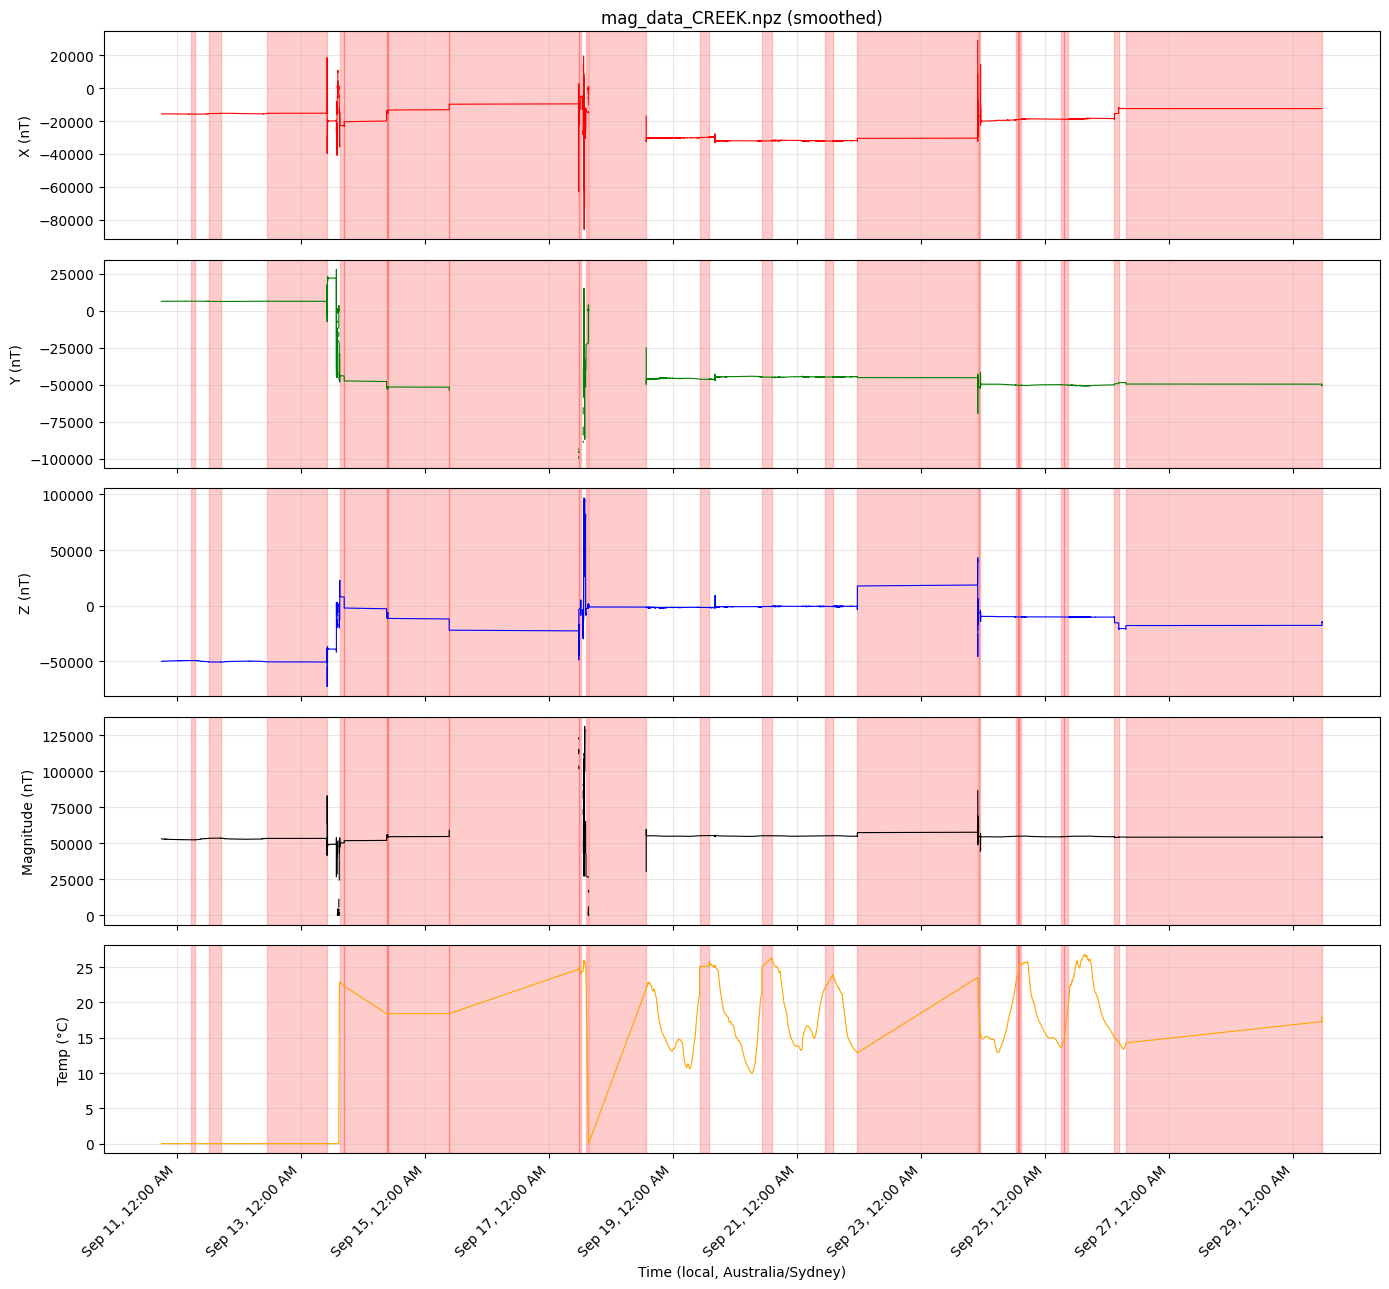

24 gap(s) > 10 min:
  2026-09-11 05:27:20+10:00 → 2026-09-11 06:55:50+10:00  (0 days 01:28:30)
  2026-09-11 12:10:40+10:00 → 2026-09-11 16:51:10+10:00  (0 days 04:40:30)
  2026-09-12 10:44:00+10:00 → 2026-09-13 09:57:08+10:00  (0 days 23:13:08)
  2026-09-13 14:57:52+10:00 → 2026-09-13 16:40:32+10:00  (0 days 01:42:40)
  2026-09-13 16:40:32+10:00 → 2026-09-14 09:05:11+10:00  (0 days 16:24:39)
  2026-09-14 09:05:11+10:00 → 2026-09-14 09:32:11+10:00  (0 days 00:27:00)
  2026-09-14 09:32:32+10:00 → 2026-09-15 09:18:20+10:00  (0 days 23:45:48)
  2026-09-15 09:18:21+10:00 → 2026-09-17 11:22:35+10:00  (2 days 02:04:14)
  2026-09-17 11:29:25+10:00 → 2026-09-17 12:14:47+10:00  (0 days 00:45:22)
  2026-09-17 14:15:37+10:00 → 2026-09-17 15:10:38+10:00  (0 days 00:55:01)
  ... and 14 more


In [22]:
plot_data('data/mag_data_CREEK.npz')

Segments: 6, k = 1.039e-03 per C


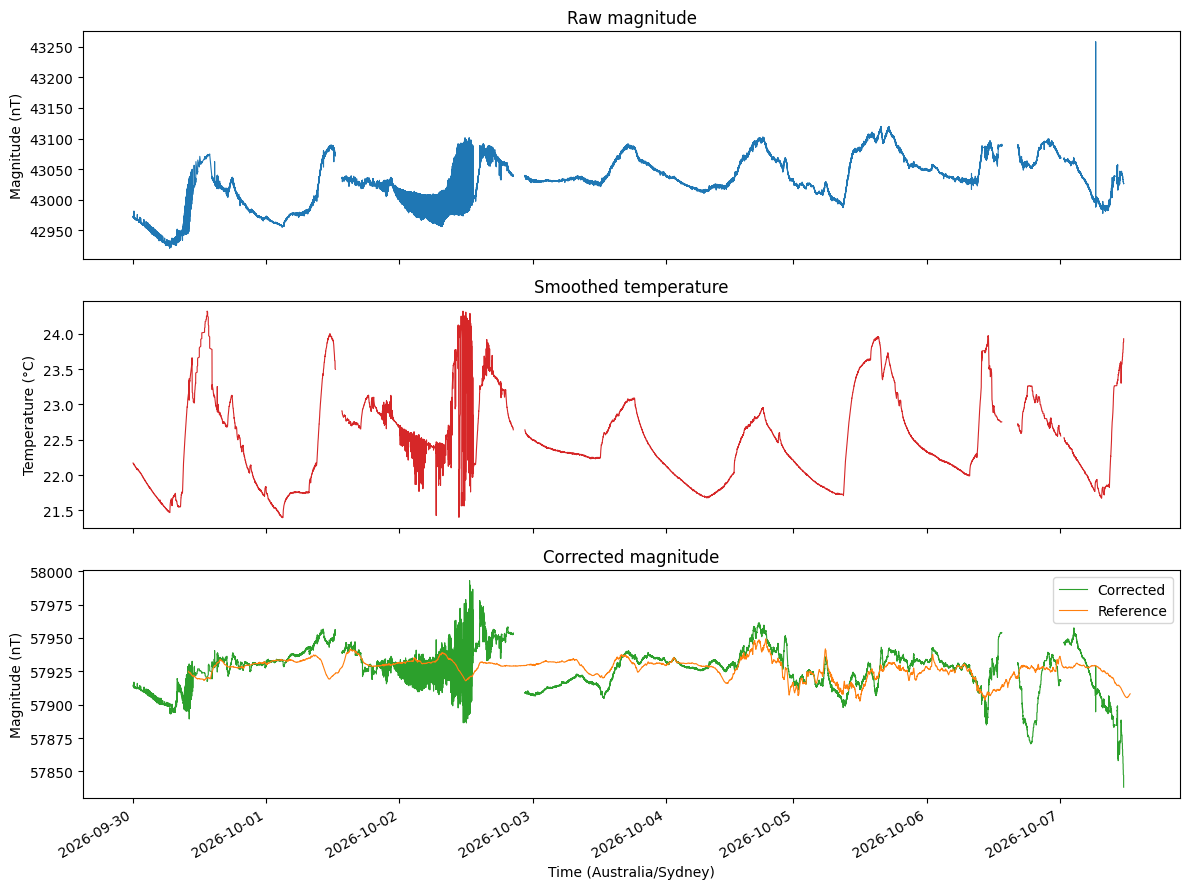

In [35]:
plot_correction('data/office-sep30-oct10.npz', ref_file='data/bom-sep30-oct10.csv', align='segment')

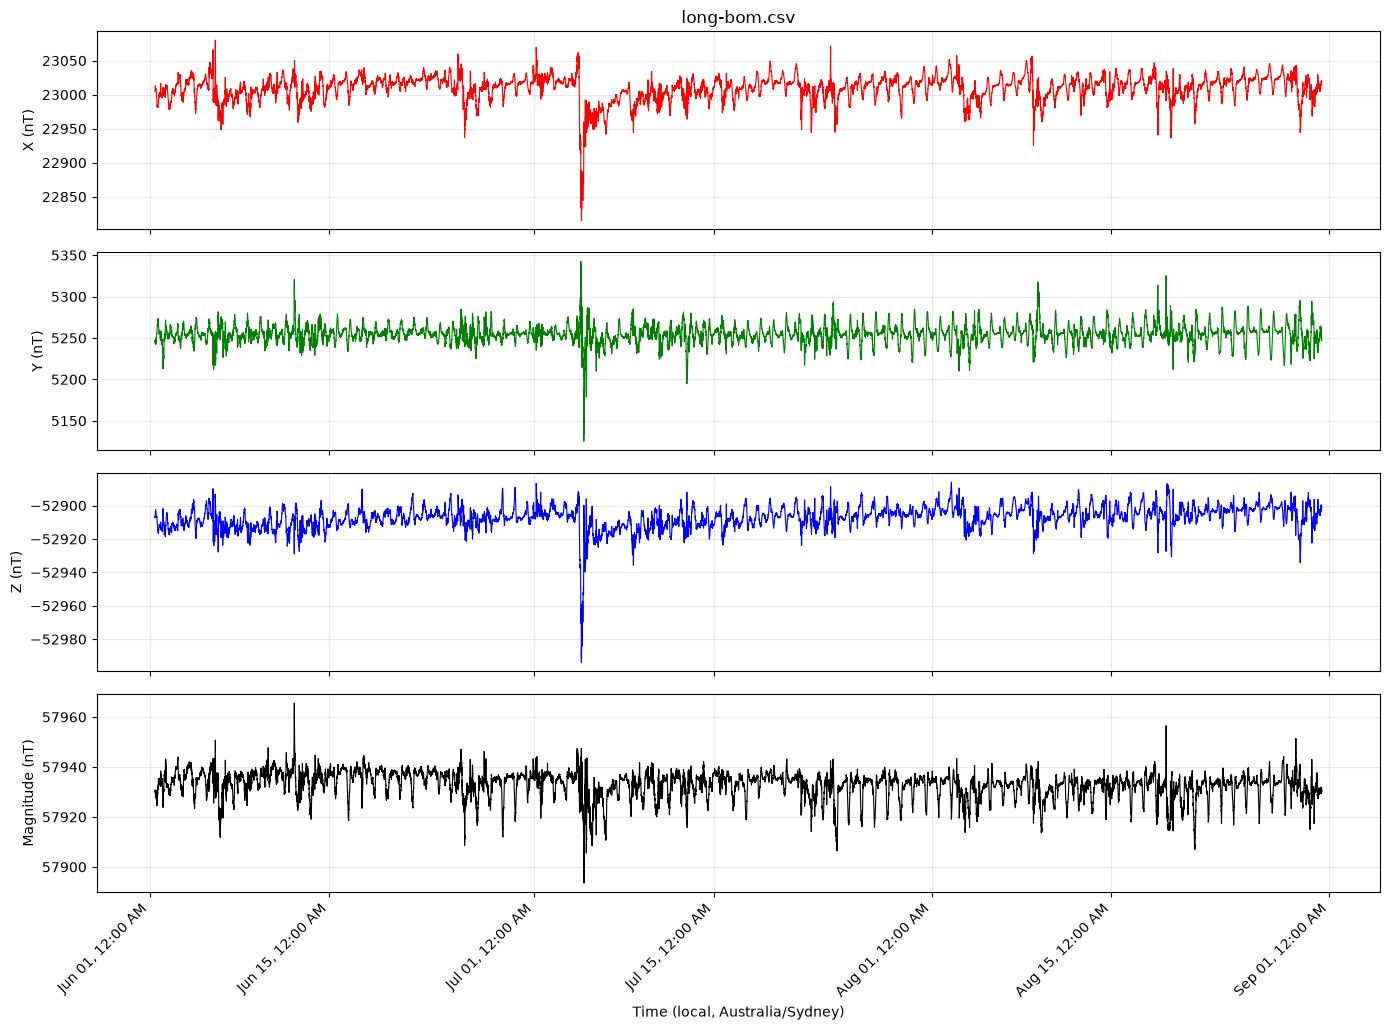

In [7]:
plot_data('data/long-bom.csv')